### Imports and configuration

In [1]:
from pathlib import Path
import os
import random
import warnings
import json
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Problem A settings
SEQ_LEN = 1
STRIDE = 1
N_SPLITS = 10
VALIDATION_SPLIT = 0.10

BATCH_SIZE = 32
EPOCHS = 80
PATIENCE = 12
LEARNING_RATE = 1e-3

DEFAULT_OPTIMIZER = "adam"
DEFAULT_LOSS = "binary_cross_entropy"

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

# Paths
KINECT_CUT_DIR   = Path("../../../data/raw/kinect_good_preprocessed")
KINECT_UNCUT_DIR = Path("../../../data/raw/kinect_good_preprocessed_not_cut/kinect_good_preprocessed_not_cut")

output_dir = Path("reporting/results")
output_dir.mkdir(parents=True, exist_ok=True)

artifact_dir = Path("reporting/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("KINECT_CUT_DIR  :", KINECT_CUT_DIR)
print("KINECT_UNCUT_DIR:", KINECT_UNCUT_DIR)


c:\Users\Ehnel\Desktop\skola\4DT907\Projekt\machine_learning_project_4dt907\ml\models\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DEVICE: cuda
GPU: NVIDIA GeForce RTX 5070 Ti
KINECT_CUT_DIR  : ..\..\..\data\raw\kinect_good_preprocessed
KINECT_UNCUT_DIR: ..\..\..\data\raw\kinect_good_preprocessed_not_cut\kinect_good_preprocessed_not_cut


### MLflow setup

In [22]:
load_dotenv("../../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A11_kinect_exercise_frame_classification_A"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()


2026/04/26 18:21:07 INFO mlflow.tracking.fluent: Experiment with name 'A11_kinect_exercise_frame_classification_A' does not exist. Creating a new experiment.


MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A11_kinect_exercise_frame_classification_A


### Kinect 3D joint definitions and base feature definitions

In [23]:
# 13 assignment joints (same as Problem B)
JOINTS_13 = [
    "head",
    "left_shoulder",
    "left_elbow",
    "right_shoulder",
    "right_elbow",
    "left_hand",
    "right_hand",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_foot",
    "right_foot",
]

# Kinect 3D: x, y, z per joint (no confidence scores)
BASE_COORD_FEATURES = [f"{j}_{axis}" for j in JOINTS_13 for axis in ["x", "y", "z"]]  # 39

FRAME_COL_CANDIDATES = ["FrameNo", "frame_index", "frame", "frame_no", "Frame", "frameno"]

print("Number of coordinate features:", len(BASE_COORD_FEATURES))
print("Example coordinate features:", BASE_COORD_FEATURES[:9])


Number of coordinate features: 39
Example coordinate features: ['head_x', 'head_y', 'head_z', 'left_shoulder_x', 'left_shoulder_y', 'left_shoulder_z', 'left_elbow_x', 'left_elbow_y', 'left_elbow_z']


### Helper functions to load Kinect data and derive labels from cut/uncut sequences

In [24]:
def find_frame_col(df: pd.DataFrame) -> str:
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def strip_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    return df


def load_kinect_uncut_df(csv_path) -> pd.DataFrame:
    """Load uncut Kinect CSV, rename FrameNo -> frame_index, return sorted by frame."""
    df = pd.read_csv(csv_path)
    df = strip_columns(df)
    frame_col = find_frame_col(df)
    df = df.rename(columns={frame_col: "frame_index"})
    # Keep only the 39 coordinate features + frame_index
    keep = ["frame_index"] + [c for c in BASE_COORD_FEATURES if c in df.columns]
    df = df[keep].copy()
    return df.sort_values("frame_index").reset_index(drop=True)


def load_kinect_cut_bounds(cut_csv_path, uncut_csv_path) -> tuple:
    """
    Uses the cut Kinect file to infer start/stop frame numbers within the uncut sequence.
    """
    cut_df   = strip_columns(pd.read_csv(cut_csv_path))
    uncut_df = strip_columns(pd.read_csv(uncut_csv_path))

    if "FrameNo" not in cut_df.columns or "FrameNo" not in uncut_df.columns:
        raise ValueError("Expected 'FrameNo' in Kinect files.")

    start_frame = int(cut_df["FrameNo"].min())
    stop_frame  = int(cut_df["FrameNo"].max())

    if start_frame < int(uncut_df["FrameNo"].min()) or stop_frame > int(uncut_df["FrameNo"].max()):
        raise ValueError("Cut frame bounds fall outside uncut Kinect sequence.")

    return start_frame, stop_frame


def add_inside_exercise_label(df: pd.DataFrame, start_frame: int, stop_frame: int) -> pd.DataFrame:
    """
    Adds binary label:
    1 = inside exercise interval [start_frame, stop_frame]
    0 = outside exercise
    """
    out = df.copy()
    out["label"] = (
        (out["frame_index"] >= start_frame) & (out["frame_index"] <= stop_frame)
    ).astype(int)
    return out


def summarize_missing_values(df: pd.DataFrame, cols: list) -> pd.Series:
    return df[cols].isna().sum().sort_values(ascending=False)


### Load example file

In [25]:
EXAMPLE_KINECT_CUT_PATH   = "../../../data/raw/kinect_good_preprocessed/A1_kinect.csv"
EXAMPLE_KINECT_UNCUT_PATH = "../../../data/raw/kinect_good_preprocessed_not_cut/kinect_good_preprocessed_not_cut/A1_kinect.csv"

example_df = load_kinect_uncut_df(EXAMPLE_KINECT_UNCUT_PATH)
start_frame, stop_frame = load_kinect_cut_bounds(
    EXAMPLE_KINECT_CUT_PATH,
    EXAMPLE_KINECT_UNCUT_PATH,
)
example_labeled_df = add_inside_exercise_label(example_df, start_frame, stop_frame)

print("Example Kinect uncut shape:", example_df.shape)
print("start_frame:", start_frame)
print("stop_frame :", stop_frame)
print("Labeled shape:", example_labeled_df.shape)


Example Kinect uncut shape: (229, 40)
start_frame: 68
stop_frame : 179
Labeled shape: (229, 41)


### Inspection cell

In [26]:
print("Columns:")
print(example_labeled_df.columns.tolist())

print("\nHead:")
display(example_labeled_df.head())

print("\nTail:")
display(example_labeled_df.tail())

print("\nClass balance:")
display(example_labeled_df["label"].value_counts().rename_axis("label").to_frame("count"))

print("\nClass proportions:")
display(
    example_labeled_df["label"]
    .value_counts(normalize=True)
    .sort_index()
    .rename_axis("label")
    .to_frame("proportion")
)

print("\nMissing values in coordinate features:")
display(summarize_missing_values(example_labeled_df, BASE_COORD_FEATURES).head(10))

print("\nFrame range:")
print(
    "min frame =", int(example_labeled_df["frame_index"].min()),
    "| max frame =", int(example_labeled_df["frame_index"].max()),
)

print("\nPositive interval check (around start):")
display(
    example_labeled_df.loc[
        (example_labeled_df["frame_index"] >= start_frame - 2) &
        (example_labeled_df["frame_index"] <= start_frame + 2),
        ["frame_index", "label"]
    ]
)
display(
    example_labeled_df.loc[
        (example_labeled_df["frame_index"] >= stop_frame - 2) &
        (example_labeled_df["frame_index"] <= stop_frame + 2),
        ["frame_index", "label"]
    ]
)


Columns:
['frame_index', 'head_x', 'head_y', 'head_z', 'left_shoulder_x', 'left_shoulder_y', 'left_shoulder_z', 'left_elbow_x', 'left_elbow_y', 'left_elbow_z', 'right_shoulder_x', 'right_shoulder_y', 'right_shoulder_z', 'right_elbow_x', 'right_elbow_y', 'right_elbow_z', 'left_hand_x', 'left_hand_y', 'left_hand_z', 'right_hand_x', 'right_hand_y', 'right_hand_z', 'left_hip_x', 'left_hip_y', 'left_hip_z', 'right_hip_x', 'right_hip_y', 'right_hip_z', 'left_knee_x', 'left_knee_y', 'left_knee_z', 'right_knee_x', 'right_knee_y', 'right_knee_z', 'left_foot_x', 'left_foot_y', 'left_foot_z', 'right_foot_x', 'right_foot_y', 'right_foot_z', 'label']

Head:


,frame_index,head_x,head_y,head_z,left_shoulder_x,left_shoulder_y,left_shoulder_z,left_elbow_x,left_elbow_y,left_elbow_z,...,right_knee_x,right_knee_y,right_knee_z,left_foot_x,left_foot_y,left_foot_z,right_foot_x,right_foot_y,right_foot_z,label
0,0,0.009962,0.75910,0.015747,-0.15673,0.46100,0.028399,-0.18256,0.20732,0.018668,...,0.11371,-0.37810,-0.030049,-0.13515,-0.74477,-0.045770,0.12980,-0.74631,-0.060231,0
1,1,0.010491,0.75974,0.017753,-0.15662,0.46125,0.029317,-0.18223,0.20594,0.020562,...,0.11378,-0.37805,-0.030093,-0.13493,-0.74433,-0.045317,0.13049,-0.74087,-0.056886,0
2,2,0.010730,0.75990,0.018405,-0.15668,0.46150,0.029991,-0.18164,0.20587,0.021215,...,0.11377,-0.37790,-0.030111,-0.13518,-0.74493,-0.045716,0.13004,-0.74171,-0.057271,0
3,3,0.010916,0.76001,0.019369,-0.15645,0.46188,0.030573,-0.18095,0.20619,0.021357,...,0.11376,-0.37788,-0.030140,-0.13517,-0.74509,-0.045595,0.13005,-0.74267,-0.057693,0
4,4,0.011140,0.75994,0.019772,-0.15642,0.46199,0.030829,-0.18034,0.20624,0.021669,...,0.11368,-0.37791,-0.030162,-0.13511,-0.74538,-0.045998,0.13040,-0.74201,-0.057177,0



Tail:


,frame_index,head_x,head_y,head_z,left_shoulder_x,left_shoulder_y,left_shoulder_z,left_elbow_x,left_elbow_y,left_elbow_z,...,right_knee_x,right_knee_y,right_knee_z,left_foot_x,left_foot_y,left_foot_z,right_foot_x,right_foot_y,right_foot_z,label
224,224,0.70583,0.70581,-0.71344,0.46846,0.50073,-0.65308,0.33706,0.30529,-0.55854,...,0.56958,-0.31394,-0.61583,0.49511,-0.62099,-0.62133,0.45006,-0.59095,-0.36362,0
225,225,0.70737,0.70684,-0.71560,0.46972,0.50096,-0.65442,0.33975,0.30459,-0.56255,...,0.57315,-0.31439,-0.61725,0.49517,-0.62096,-0.62144,0.45351,-0.58935,-0.36300,0
226,226,0.70847,0.70759,-0.71710,0.47428,0.50030,-0.65858,0.34196,0.30433,-0.56591,...,0.58011,-0.31726,-0.61859,0.49551,-0.62137,-0.62146,0.45686,-0.53568,-0.31854,0
227,227,0.70952,0.70850,-0.71820,0.47570,0.50076,-0.66070,0.34416,0.30302,-0.57032,...,0.63657,-0.31717,-0.61599,0.49602,-0.62250,-0.62156,0.47012,-0.52686,-0.32841,0
228,228,0.71070,0.70969,-0.71881,0.47740,0.50144,-0.66342,0.34756,0.30022,-0.57827,...,0.64207,-0.32193,-0.62377,0.49839,-0.63422,-0.62000,0.52176,-0.51939,-0.30875,0



Class balance:


,count
label,
0,117
1,112


... (3 outputs left out)

head_x          0
left_knee_z     0
left_hip_y      0
left_hip_z      0
right_hip_x     0
right_hip_y     0
right_hip_z     0
left_knee_x     0
left_knee_y     0
right_knee_x    0
dtype: int64


Frame range:
min frame = 0 | max frame = 228

Positive interval check (around start):


,frame_index,label
66,66,0
67,67,0
68,68,1
69,69,1
70,70,1


,frame_index,label
177,177,1
178,178,1
179,179,1
180,180,0
181,181,0


### Quick visual sanity check

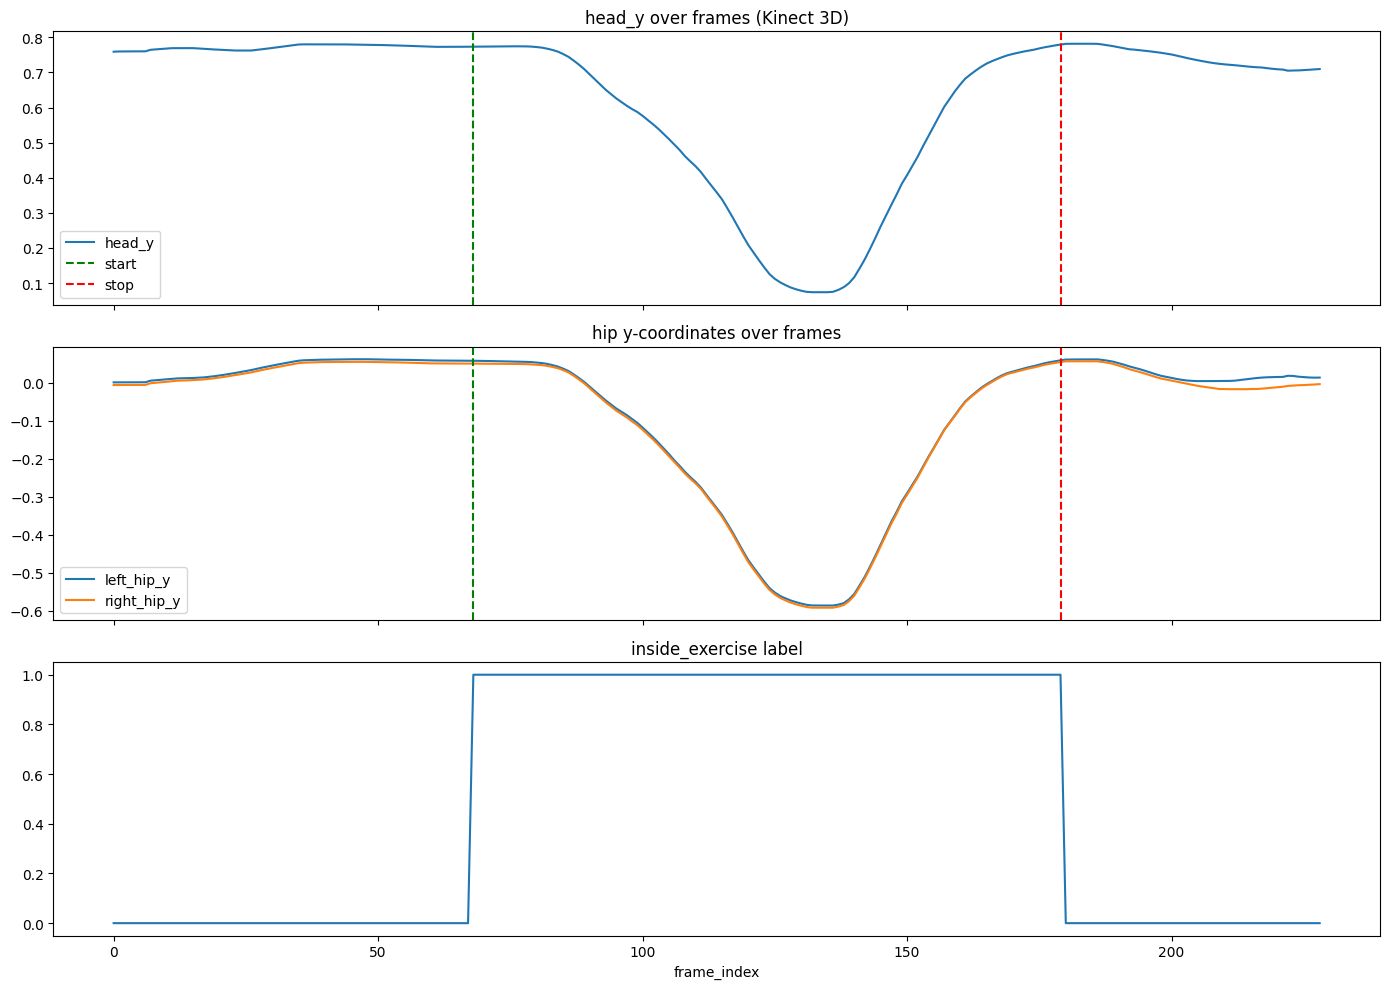

In [27]:
plot_df = example_labeled_df.copy()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(plot_df["frame_index"], plot_df["head_y"], label="head_y")
axes[0].axvline(start_frame, linestyle="--", color="green", label="start")
axes[0].axvline(stop_frame,  linestyle="--", color="red",   label="stop")
axes[0].set_title("head_y over frames (Kinect 3D)")
axes[0].legend()

axes[1].plot(plot_df["frame_index"], plot_df["left_hip_y"],  label="left_hip_y")
axes[1].plot(plot_df["frame_index"], plot_df["right_hip_y"], label="right_hip_y")
axes[1].axvline(start_frame, linestyle="--", color="green")
axes[1].axvline(stop_frame,  linestyle="--", color="red")
axes[1].legend()
axes[1].set_title("hip y-coordinates over frames")

axes[2].plot(plot_df["frame_index"], plot_df["label"], label="label")
axes[2].set_title("inside_exercise label")
axes[2].set_xlabel("frame_index")

plt.tight_layout()
plt.show()


### Normalize coordinates, distance calculation, angles and velocity features

In [28]:
def add_normalized_coordinates(df: pd.DataFrame) -> pd.DataFrame:
    # Normalize x,y,z per frame using hip center and 3D torso size
    out = df.copy()

    for axis in ["x", "y", "z"]:
        out[f"hip_center_{axis}"]      = (out[f"left_hip_{axis}"]      + out[f"right_hip_{axis}"])      / 2.0
        out[f"shoulder_center_{axis}"] = (out[f"left_shoulder_{axis}"] + out[f"right_shoulder_{axis}"]) / 2.0

    torso_size = np.sqrt(
        (out["shoulder_center_x"] - out["hip_center_x"]) ** 2 +
        (out["shoulder_center_y"] - out["hip_center_y"]) ** 2 +
        (out["shoulder_center_z"] - out["hip_center_z"]) ** 2
    )
    out["torso_size"] = torso_size.replace(0, np.nan)
    out["torso_size"] = out["torso_size"].fillna(out["torso_size"].median())
    out["torso_size"] = out["torso_size"].clip(lower=1e-6)

    for joint in JOINTS_13:
        for axis in ["x", "y", "z"]:
            out[f"{joint}_{axis}_norm"] = (
                out[f"{joint}_{axis}"] - out[f"hip_center_{axis}"]
            ) / out["torso_size"]

    return out


def add_selected_distances(df: pd.DataFrame) -> pd.DataFrame:
    # Add normalized 3D distances between key joint pairs
    out = df.copy()

    def dist3d(j1, j2, name):
        dx = out[f"{j1}_x_norm"] - out[f"{j2}_x_norm"]
        dy = out[f"{j1}_y_norm"] - out[f"{j2}_y_norm"]
        dz = out[f"{j1}_z_norm"] - out[f"{j2}_z_norm"]
        out[name] = np.sqrt(dx**2 + dy**2 + dz**2)

    dist3d("left_hip",      "left_knee",   "dist_left_hip_knee")
    dist3d("right_hip",     "right_knee",  "dist_right_hip_knee")
    dist3d("left_knee",     "left_foot",   "dist_left_knee_foot")
    dist3d("right_knee",    "right_foot",  "dist_right_knee_foot")
    dist3d("head",          "left_hip",    "dist_head_left_hip")
    dist3d("head",          "right_hip",   "dist_head_right_hip")
    dist3d("left_hand",     "left_knee",   "dist_left_hand_left_knee")
    dist3d("right_hand",    "right_knee",  "dist_right_hand_right_knee")
    dist3d("left_hip",      "right_hip",   "dist_hip_width")
    dist3d("left_shoulder", "right_shoulder", "dist_shoulder_width")

    return out


def add_selected_angles(df: pd.DataFrame) -> pd.DataFrame:
    # Add 3D joint angles using dot product of normalized limb vectors
    out = df.copy()

    def angle3d(a, b, c, name):
        bax = out[f"{a}_x_norm"] - out[f"{b}_x_norm"]
        bay = out[f"{a}_y_norm"] - out[f"{b}_y_norm"]
        baz = out[f"{a}_z_norm"] - out[f"{b}_z_norm"]
        bcx = out[f"{c}_x_norm"] - out[f"{b}_x_norm"]
        bcy = out[f"{c}_y_norm"] - out[f"{b}_y_norm"]
        bcz = out[f"{c}_z_norm"] - out[f"{b}_z_norm"]

        dot   = bax * bcx + bay * bcy + baz * bcz
        norm1 = np.sqrt(bax**2 + bay**2 + baz**2)
        norm2 = np.sqrt(bcx**2 + bcy**2 + bcz**2)
        denom = (norm1 * norm2).clip(lower=1e-6)

        out[name] = np.arccos(np.clip(dot / denom, -1.0, 1.0))

    angle3d("left_shoulder",  "left_hip",   "left_knee",   "angle_left_hip")
    angle3d("right_shoulder", "right_hip",  "right_knee",  "angle_right_hip")
    angle3d("left_hip",       "left_knee",  "left_foot",   "angle_left_knee")
    angle3d("right_hip",      "right_knee", "right_foot",  "angle_right_knee")
    angle3d("left_elbow",     "left_shoulder",  "left_hip",  "angle_left_shoulder")
    angle3d("right_elbow",    "right_shoulder", "right_hip", "angle_right_shoulder")

    return out


def add_simple_velocity_features(df: pd.DataFrame) -> pd.DataFrame:
    # Per-frame delta (velocity) for all normalized coordinates
    out = df.copy()
    norm_cols = [f"{j}_{axis}_norm" for j in JOINTS_13 for axis in ["x", "y", "z"]]
    for col in norm_cols:
        out[f"{col}_vel"] = out[col].diff().fillna(0.0)
    return out


### Test with example and double checking nothing is missing

In [29]:
example_feat_df = example_labeled_df.copy()
example_feat_df = add_normalized_coordinates(example_feat_df)
example_feat_df = add_selected_distances(example_feat_df)
example_feat_df = add_selected_angles(example_feat_df)
example_feat_df = add_simple_velocity_features(example_feat_df)

NORM_COORD_FEATURES = [f"{j}_{axis}_norm" for j in JOINTS_13 for axis in ["x", "y", "z"]]  # 39
DISTANCE_FEATURES = [
    "dist_left_hip_knee",
    "dist_right_hip_knee",
    "dist_left_knee_foot",
    "dist_right_knee_foot",
    "dist_head_left_hip",
    "dist_head_right_hip",
    "dist_left_hand_left_knee",
    "dist_right_hand_right_knee",
    "dist_hip_width",
    "dist_shoulder_width",
]
ANGLE_FEATURES = [
    "angle_left_hip",
    "angle_right_hip",
    "angle_left_knee",
    "angle_right_knee",
    "angle_left_shoulder",
    "angle_right_shoulder",
]
VELOCITY_FEATURES = [f"{col}_vel" for col in NORM_COORD_FEATURES]  # 39

FEATURE_SETS = {
    "coords_only":              BASE_COORD_FEATURES,
    "norm_coords":              NORM_COORD_FEATURES,
    "engineered_small":         NORM_COORD_FEATURES + DISTANCE_FEATURES + ANGLE_FEATURES,
    "engineered_with_velocity": NORM_COORD_FEATURES + DISTANCE_FEATURES + ANGLE_FEATURES + VELOCITY_FEATURES,
}

for name, cols in FEATURE_SETS.items():
    print(f"{name:30s} -> {len(cols)} features")


coords_only                    -> 39 features
norm_coords                    -> 39 features
engineered_small               -> 55 features
engineered_with_velocity       -> 94 features


In [30]:
display(
    example_feat_df[
        ["frame_index", "label"] +
        NORM_COORD_FEATURES[:6] +
        DISTANCE_FEATURES[:3] +
        ANGLE_FEATURES[:2]
    ].head()
)

missing_checks = {
    name: example_feat_df[cols].isna().sum().sum()
    for name, cols in FEATURE_SETS.items()
}
print("Missing values per feature set:", missing_checks)


,frame_index,label,head_x_norm,head_y_norm,head_z_norm,left_shoulder_x_norm,left_shoulder_y_norm,left_shoulder_z_norm,dist_left_hip_knee,dist_right_hip_knee,dist_left_knee_foot,angle_left_hip,angle_right_hip
0,0,0,0.016950,1.632339,0.110961,-0.340181,0.993671,0.138068,0.805638,0.801354,0.802696,2.784006,2.809190
1,1,0,0.017446,1.633069,0.114612,-0.340488,0.993735,0.139381,0.805341,0.801316,0.801465,2.784478,2.810726
2,2,0,0.017818,1.633014,0.115670,-0.340728,0.993924,0.140484,0.805260,0.801307,0.802813,2.784082,2.810844
3,3,0,0.017995,1.632657,0.117502,-0.340338,0.994356,0.141490,0.805028,0.801083,0.802862,2.784356,2.810978
4,4,0,0.018399,1.632308,0.118180,-0.340308,0.994467,0.141850,0.804910,0.801024,0.803322,2.784892,2.811314


Missing values per feature set: {'coords_only': 0, 'norm_coords': 0, 'engineered_small': 0, 'engineered_with_velocity': 0}


### Windowing helpers for c frames

In [31]:
def make_sequence_windows(
    df: pd.DataFrame,
    feature_cols: list,
    label_col: str = "label",
    seq_len: int = 1,
    stride: int = 1,
    center_label: bool = True,
):
    # Convert sequence df into windowed samples. seq_len=1 -> one frame per sample.
    values    = df[feature_cols].to_numpy(dtype=np.float32)
    labels    = df[label_col].to_numpy(dtype=np.float32)
    frame_ids = df["frame_index"].to_numpy(dtype=np.int32)

    X_list, y_list, frame_ref_list = [], [], []

    if seq_len == 1:
        for i in range(0, len(df), stride):
            X_list.append(values[i:i+1])
            y_list.append(labels[i])
            frame_ref_list.append(frame_ids[i])
    else:
        for start in range(0, len(df) - seq_len + 1, stride):
            end = start + seq_len
            window_x = values[start:end]
            if center_label:
                ci = start + seq_len // 2
                y_val = labels[ci]; frame_ref = frame_ids[ci]
            else:
                y_val = labels[end - 1]; frame_ref = frame_ids[end - 1]
            X_list.append(window_x)
            y_list.append(y_val)
            frame_ref_list.append(frame_ref)

    X = np.stack(X_list).astype(np.float32)
    y = np.array(y_list, dtype=np.float32)
    frame_refs = np.array(frame_ref_list, dtype=np.int32)
    return X, y, frame_refs


def flatten_if_needed(X: np.ndarray) -> np.ndarray:
    return X.reshape(X.shape[0], -1)


### Create first baseline dataset from the example file

In [32]:
BASELINE_FEATURE_SET_NAME = "engineered_small"
BASELINE_FEATURES = FEATURE_SETS[BASELINE_FEATURE_SET_NAME]

SEQ_LEN = 1
STRIDE  = 1

X_example, y_example, frame_refs_example = make_sequence_windows(
    example_feat_df,
    feature_cols=BASELINE_FEATURES,
    label_col="label",
    seq_len=SEQ_LEN,
    stride=STRIDE,
)

X_example_flat = flatten_if_needed(X_example)

print("Feature set:", BASELINE_FEATURE_SET_NAME)
print("X_example shape:", X_example.shape)
print("X_example_flat shape:", X_example_flat.shape)
print("y_example shape:", y_example.shape)
print("Positive rate:", y_example.mean())
print("First 10 frame refs:", frame_refs_example[:10])


Feature set: engineered_small
X_example shape: (229, 1, 55)
X_example_flat shape: (229, 55)
y_example shape: (229,)
Positive rate: 0.48908296
First 10 frame refs: [0 1 2 3 4 5 6 7 8 9]


### Dataset class and dense classifier

In [33]:
class FrameWindowDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class DenseBinaryClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dims=(128, 64), dropout=0.2):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


### Train/validation split on the example file

In [34]:
X_train, X_val, y_train, y_val, frames_train, frames_val = train_test_split(
    X_example_flat,
    y_example,
    frame_refs_example,
    test_size=VALIDATION_SPLIT,
    random_state=RANDOM_SEED,
    stratify=y_example,
)

print("Train shape:", X_train.shape, y_train.shape)
print("Val shape:", X_val.shape, y_val.shape)
print("Train positive rate:", y_train.mean())
print("Val positive rate:", y_val.mean())


Train shape: (206, 55) (206,)
Val shape: (23, 55) (23,)
Train positive rate: 0.49029127
Val positive rate: 0.47826087


### Standardization

In [35]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)

print("Scaled train mean (approx):", X_train_scaled.mean().round(4))
print("Scaled train std  (approx):", X_train_scaled.std().round(4))


Scaled train mean (approx): 0.0
Scaled train std  (approx): 1.0


### Class imbalance handling

In [36]:
n_pos = int(y_train.sum())
n_neg = int(len(y_train) - n_pos)

pos_weight_value  = n_neg / max(n_pos, 1)
pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=DEVICE)

print("n_neg:", n_neg)
print("n_pos:", n_pos)
print("pos_weight:", float(pos_weight_value))


n_neg: 105
n_pos: 101
pos_weight: 1.0396039603960396


### Training utilities

In [37]:
def get_optimizer(model: nn.Module, optimizer_name: str, learning_rate: float):
    name = optimizer_name.lower()
    if name == "adam":
        return torch.optim.Adam(model.parameters(), lr=learning_rate)
    elif name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=learning_rate)
    elif name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")


def evaluate_binary_classifier(model, loader, loss_fn, threshold=0.5):
    model.eval()
    losses, all_probs, all_preds, all_targets = [], [], [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(X_batch)
            loss   = loss_fn(logits, y_batch)
            probs  = torch.sigmoid(logits)
            preds  = (probs >= threshold).float()

            losses.append(loss.item())
            all_probs.extend(probs.cpu().numpy().tolist())
            all_preds.extend(preds.cpu().numpy().tolist())
            all_targets.extend(y_batch.cpu().numpy().tolist())

    y_true = np.array(all_targets).astype(int)
    y_pred = np.array(all_preds).astype(int)

    return {
        "loss":             float(np.mean(losses)),
        "precision":        float(precision_score(y_true, y_pred, zero_division=0)),
        "recall":           float(recall_score(y_true, y_pred, zero_division=0)),
        "f1":               float(f1_score(y_true, y_pred, zero_division=0)),
        "confusion_matrix": confusion_matrix(y_true, y_pred),
    }


def train_binary_classifier(
    model,
    train_loader,
    val_loader,
    optimizer_name="adam",
    learning_rate=1e-3,
    epochs=80,
    patience=12,
    pos_weight=None,
    threshold=0.5,
):
    optimizer = get_optimizer(model, optimizer_name, learning_rate)
    loss_fn   = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    history = []
    best_state = None
    best_val_loss = float("inf")
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        train_loss  = float(np.mean(train_losses))
        val_metrics = evaluate_binary_classifier(model, val_loader, loss_fn, threshold)

        row = {
            "epoch": epoch, "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_precision": val_metrics["precision"],
            "val_recall":    val_metrics["recall"],
            "val_f1":        val_metrics["f1"],
        }
        history.append(row)

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch % 10 == 0 or epoch == 1:
            print(
                f"Epoch {epoch:03d} | train_loss={train_loss:.4f} | "
                f"val_loss={val_metrics['loss']:.4f} | "
                f"precision={val_metrics['precision']:.4f} | "
                f"recall={val_metrics['recall']:.4f} | "
                f"f1={val_metrics['f1']:.4f}"
            )

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, pd.DataFrame(history)


### Train one baseline model on the example sequence

In [38]:
train_dataset = FrameWindowDataset(X_train_scaled, y_train)
val_dataset   = FrameWindowDataset(X_val_scaled,   y_val)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

input_dim = X_train_scaled.shape[1]
model = DenseBinaryClassifier(input_dim=input_dim, hidden_dims=(128, 64), dropout=0.2).to(DEVICE)

model, history_df = train_binary_classifier(
    model, train_loader, val_loader,
    optimizer_name="adam", learning_rate=LEARNING_RATE,
    epochs=EPOCHS, patience=PATIENCE,
    pos_weight=pos_weight_tensor, threshold=0.5,
)

history_df.tail()


Epoch 001 | train_loss=0.6669 | val_loss=0.5948 | precision=1.0000 | recall=0.5455 | f1=0.7059
Epoch 010 | train_loss=0.1339 | val_loss=0.1446 | precision=1.0000 | recall=0.9091 | f1=0.9524
Epoch 020 | train_loss=0.0750 | val_loss=0.0871 | precision=1.0000 | recall=0.9091 | f1=0.9524
Epoch 030 | train_loss=0.0526 | val_loss=0.0512 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 040 | train_loss=0.0625 | val_loss=0.0582 | precision=1.0000 | recall=0.9091 | f1=0.9524
Epoch 050 | train_loss=0.0387 | val_loss=0.0227 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 060 | train_loss=0.0299 | val_loss=0.0155 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 070 | train_loss=0.0369 | val_loss=0.0105 | precision=1.0000 | recall=1.0000 | f1=1.0000
Epoch 080 | train_loss=0.0169 | val_loss=0.0106 | precision=1.0000 | recall=1.0000 | f1=1.0000


,epoch,train_loss,val_loss,val_precision,val_recall,val_f1
75,76,0.024476,0.012409,1.0,1.0,1.0
76,77,0.023406,0.006565,1.0,1.0,1.0
77,78,0.029181,0.007304,1.0,1.0,1.0
78,79,0.021486,0.006060,1.0,1.0,1.0
79,80,0.016899,0.010608,1.0,1.0,1.0


### Inspect baseline validation performance

In [39]:
val_loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
val_metrics = evaluate_binary_classifier(model, val_loader, val_loss_fn, threshold=0.5)

print("Validation metrics:")
for k, v in val_metrics.items():
    if k != "confusion_matrix":
        print(f"  {k}: {v}")

print("\nConfusion matrix:")
print(val_metrics["confusion_matrix"])

print("\nClassification report:")
with torch.no_grad():
    logits = model(torch.tensor(X_val_scaled, dtype=torch.float32, device=DEVICE))
    probs  = torch.sigmoid(logits).cpu().numpy()
    preds  = (probs >= 0.5).astype(int)

print(classification_report(y_val.astype(int), preds, zero_division=0))


Validation metrics:
  loss: 0.006060414481908083
  precision: 1.0
  recall: 1.0
  f1: 1.0

Confusion matrix:
[[12  0]
 [ 0 11]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      1.00      1.00        11

    accuracy                           1.00        23
   macro avg       1.00      1.00      1.00        23
weighted avg       1.00      1.00      1.00        23



Note: the single-sequence validation score is noisy (high variance from one sequence). The grouped cross-validation over all sequences below gives a much more reliable estimate.

### File matching helpers

In [40]:
import re

def stem_base(name: str) -> str:
    stem = Path(name).stem
    stem = stem.replace("_kinect_uncut", "")
    stem = stem.replace("_kinect", "")
    return stem


def list_csv_files(folder: Path) -> list:
    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder}")
    return sorted(folder.glob("*.csv"))


def build_file_pairs(kinect_cut_dir: Path, kinect_uncut_dir: Path) -> pd.DataFrame:
    cut_files   = list_csv_files(kinect_cut_dir)
    uncut_files = list_csv_files(kinect_uncut_dir)

    cut_map   = {stem_base(p.name): p for p in cut_files}
    uncut_map = {stem_base(p.name): p for p in uncut_files}

    common_keys = sorted(set(cut_map) & set(uncut_map))

    rows = []
    for key in common_keys:
        rows.append({
            "sequence_id":       key,
            "kinect_cut_path":   str(cut_map[key]),
            "kinect_uncut_path": str(uncut_map[key]),
        })

    return pd.DataFrame(rows)


### Load all labeled sequences

In [41]:
def build_labeled_sequence_df(kinect_cut_path, kinect_uncut_path, sequence_id):
    seq_df = load_kinect_uncut_df(kinect_uncut_path)
    start_frame, stop_frame = load_kinect_cut_bounds(kinect_cut_path, kinect_uncut_path)
    seq_df = add_inside_exercise_label(seq_df, start_frame, stop_frame)
    seq_df["sequence_id"] = sequence_id
    seq_df["start_frame"] = start_frame
    seq_df["stop_frame"]  = stop_frame
    return seq_df


def load_all_labeled_sequences(pairs_df: pd.DataFrame) -> pd.DataFrame:
    parts = []
    for _, row in pairs_df.iterrows():
        seq_df = build_labeled_sequence_df(
            row["kinect_cut_path"],
            row["kinect_uncut_path"],
            row["sequence_id"],
        )
        parts.append(seq_df)
    if not parts:
        raise ValueError("No matched file pairs found.")
    return pd.concat(parts, ignore_index=True)


### Inspect matched files and full dataset

In [42]:
pairs_df = build_file_pairs(KINECT_CUT_DIR, KINECT_UNCUT_DIR)
print("Matched sequences:", len(pairs_df))
display(pairs_df.head())

all_df = load_all_labeled_sequences(pairs_df)
print("All rows:", len(all_df))
print("Unique sequences:", all_df["sequence_id"].nunique())

display(
    all_df.groupby("sequence_id")["label"]
    .agg(["count", "sum", "mean"])
    .rename(columns={"sum": "positive_frames", "mean": "positive_rate"})
    .head(10)
)


Matched sequences: 179


,sequence_id,kinect_cut_path,kinect_uncut_path
0,A1,..\..\..\data\raw\kinect_good_preprocessed\A1_...,..\..\..\data\raw\kinect_good_preprocessed_not...
1,A10,..\..\..\data\raw\kinect_good_preprocessed\A10...,..\..\..\data\raw\kinect_good_preprocessed_not...
2,A100,..\..\..\data\raw\kinect_good_preprocessed\A10...,..\..\..\data\raw\kinect_good_preprocessed_not...
3,A101,..\..\..\data\raw\kinect_good_preprocessed\A10...,..\..\..\data\raw\kinect_good_preprocessed_not...
4,A102,..\..\..\data\raw\kinect_good_preprocessed\A10...,..\..\..\data\raw\kinect_good_preprocessed_not...


All rows: 37782
Unique sequences: 179


,count,positive_frames,positive_rate
sequence_id,,,
A1,229,112,0.489083
A10,257,161,0.626459
A100,163,163,1.000000
A101,229,229,1.000000
A102,206,206,1.000000
A103,168,168,1.000000
A104,198,153,0.772727
A105,210,146,0.695238
A106,204,159,0.779412


### Add engineered features to all sequences

In [43]:
all_feat_df = all_df.copy()
all_feat_df = add_normalized_coordinates(all_feat_df)
all_feat_df = add_selected_distances(all_feat_df)
all_feat_df = add_selected_angles(all_feat_df)
all_feat_df = add_simple_velocity_features(all_feat_df)

print("Shape after feature engineering:", all_feat_df.shape)

display(
    all_feat_df[
        ["sequence_id", "frame_index", "label"] +
        NORM_COORD_FEATURES[:4] +
        DISTANCE_FEATURES[:2] +
        ANGLE_FEATURES[:2]
    ].head()
)


Shape after feature engineering: (37782, 145)


,sequence_id,frame_index,label,head_x_norm,head_y_norm,head_z_norm,left_shoulder_x_norm,dist_left_hip_knee,dist_right_hip_knee,angle_left_hip,angle_right_hip
0,A1,0,0,0.016950,1.632339,0.110961,-0.340181,0.805638,0.801354,2.784006,2.809190
1,A1,1,0,0.017446,1.633069,0.114612,-0.340488,0.805341,0.801316,2.784478,2.810726
2,A1,2,0,0.017818,1.633014,0.115670,-0.340728,0.805260,0.801307,2.784082,2.810844
3,A1,3,0,0.017995,1.632657,0.117502,-0.340338,0.805028,0.801083,2.784356,2.810978
4,A1,4,0,0.018399,1.632308,0.118180,-0.340308,0.804910,0.801024,2.784892,2.811314


### Build windows for all sequences

In [44]:
def make_windows_for_all_sequences(
    df: pd.DataFrame,
    feature_cols: list,
    seq_len: int = 1,
    stride: int = 1,
    label_col: str = "label",
):
    X_parts, y_parts, frame_ref_parts = [], [], []
    seq_id_parts, start_parts, stop_parts = [], [], []

    for sequence_id, seq_df in df.groupby("sequence_id"):
        seq_df = seq_df.sort_values("frame_index").reset_index(drop=True)

        X_seq, y_seq, frame_refs_seq = make_sequence_windows(
            seq_df, feature_cols=feature_cols,
            label_col=label_col, seq_len=seq_len, stride=stride, center_label=True,
        )

        X_parts.append(X_seq)
        y_parts.append(y_seq)
        frame_ref_parts.append(frame_refs_seq)
        seq_id_parts.append(np.array([sequence_id] * len(y_seq), dtype=object))
        start_parts.append(np.array([seq_df["start_frame"].iloc[0]] * len(y_seq)))
        stop_parts.append(np.array([seq_df["stop_frame"].iloc[0]] * len(y_seq)))

    X         = np.concatenate(X_parts,         axis=0)
    y         = np.concatenate(y_parts,         axis=0)
    frame_refs = np.concatenate(frame_ref_parts, axis=0)
    seq_ids   = np.concatenate(seq_id_parts,    axis=0)
    starts    = np.concatenate(start_parts,     axis=0)
    stops     = np.concatenate(stop_parts,      axis=0)

    meta_df = pd.DataFrame({
        "sequence_id": seq_ids,
        "frame_ref":   frame_refs,
        "label":       y.astype(int),
        "start_frame": starts.astype(int),
        "stop_frame":  stops.astype(int),
    })

    return X, y.astype(np.float32), meta_df


### Proper grouped train/test split

In [45]:
def split_sequences_train_test(pairs_df: pd.DataFrame, test_size=0.10, random_state=42):
    seq_ids = pairs_df["sequence_id"].tolist()
    train_ids, test_ids = train_test_split(seq_ids, test_size=test_size, random_state=random_state)
    return set(train_ids), set(test_ids)


train_sequence_ids, test_sequence_ids = split_sequences_train_test(
    pairs_df, test_size=0.10, random_state=RANDOM_SEED)

print("Train sequences:", len(train_sequence_ids))
print("Test sequences:", len(test_sequence_ids))
print("Example test IDs:", sorted(list(test_sequence_ids))[:10])


Train sequences: 161
Test sequences: 18
Example test IDs: ['A113', 'A114', 'A117', 'A121', 'A138', 'A140', 'A159', 'A16', 'A17', 'A25']


### Fast experiment prep

In [46]:
FAST_FEATURE_SET_NAMES = [
    "coords_only",
    "norm_coords",
    "engineered_small",
]

FAST_SEQ_LENS       = [1, 5]
FAST_HIDDEN_CONFIGS = [(64,), (128, 64)]
FAST_DROPOUTS       = [0.1, 0.3]
FAST_OPTIMIZERS     = ["adam"]
FAST_BATCH_SIZE     = 32
FAST_EPOCHS         = 20
FAST_PATIENCE       = 5
FAST_STRIDE         = 1
FAST_THRESHOLD      = 0.5


### Cross-validation helpers on training sequences only

In [47]:
def prepare_train_test_arrays(feature_set_name: str, seq_len: int):
    feature_cols = FEATURE_SETS[feature_set_name]

    train_df = all_feat_df[all_feat_df["sequence_id"].isin(train_sequence_ids)].copy()
    test_df  = all_feat_df[all_feat_df["sequence_id"].isin(test_sequence_ids)].copy()

    X_train_all, y_train_all, meta_train = make_windows_for_all_sequences(
        train_df, feature_cols=feature_cols, seq_len=seq_len, stride=FAST_STRIDE)

    X_test, y_test, meta_test = make_windows_for_all_sequences(
        test_df, feature_cols=feature_cols, seq_len=seq_len, stride=FAST_STRIDE)

    return X_train_all, y_train_all, meta_train, X_test, y_test, meta_test


def run_one_fold(
    X_train_all_flat, y_train_all, meta_train,
    train_idx, val_idx,
    hidden_dims, dropout, optimizer_name,
    batch_size, epochs, patience, threshold=0.5,
):
    X_tr, y_tr = X_train_all_flat[train_idx], y_train_all[train_idx]
    X_va, y_va = X_train_all_flat[val_idx],   y_train_all[val_idx]

    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_va = scaler.transform(X_va)

    n_pos = int(y_tr.sum()); n_neg = int(len(y_tr) - n_pos)
    pw    = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32, device=DEVICE)

    tr_loader  = DataLoader(FrameWindowDataset(X_tr, y_tr), batch_size=batch_size,
                            shuffle=True,  num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    val_loader = DataLoader(FrameWindowDataset(X_va, y_va), batch_size=batch_size,
                            shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

    model = DenseBinaryClassifier(
        input_dim=X_tr.shape[1], hidden_dims=hidden_dims, dropout=dropout).to(DEVICE)

    model, _ = train_binary_classifier(
        model, tr_loader, val_loader,
        optimizer_name=optimizer_name, learning_rate=LEARNING_RATE,
        epochs=epochs, patience=patience, pos_weight=pw, threshold=threshold)

    val_metrics = evaluate_binary_classifier(
        model, val_loader, nn.BCEWithLogitsLoss(pos_weight=pw), threshold=threshold)

    return {
        "precision": val_metrics["precision"],
        "recall":    val_metrics["recall"],
        "f1":        val_metrics["f1"],
        "loss":      val_metrics["loss"],
    }


### Fast grouped CV experiment loop

In [48]:
def run_fast_cv_search():
    results = []

    for feature_set_name in FAST_FEATURE_SET_NAMES:
        for seq_len in FAST_SEQ_LENS:
            print(f"\n=== Feature set: {feature_set_name} | seq_len: {seq_len} ===")

            X_train_all, y_train_all, meta_train, X_test, y_test, meta_test = \
                prepare_train_test_arrays(feature_set_name, seq_len)

            X_train_all_flat = flatten_if_needed(X_train_all)
            groups = meta_train["sequence_id"].values
            n_splits_here = min(N_SPLITS, len(np.unique(groups)))

            if n_splits_here < 2:
                print("Skipping: not enough train sequences for grouped CV.")
                continue

            gkf = GroupKFold(n_splits=n_splits_here)

            for hidden_dims in FAST_HIDDEN_CONFIGS:
                for dropout in FAST_DROPOUTS:
                    for optimizer_name in FAST_OPTIMIZERS:
                        fold_rows = []

                        for fold, (tr_idx, val_idx) in enumerate(
                            gkf.split(X_train_all_flat, y_train_all, groups=groups), start=1
                        ):
                            res = run_one_fold(
                                X_train_all_flat, y_train_all, meta_train,
                                tr_idx, val_idx, hidden_dims, dropout, optimizer_name,
                                FAST_BATCH_SIZE, FAST_EPOCHS, FAST_PATIENCE, FAST_THRESHOLD,
                            )
                            row = {
                                "feature_set": feature_set_name, "seq_len": seq_len,
                                "hidden_dims": str(hidden_dims), "dropout": dropout,
                                "optimizer": optimizer_name, "fold": fold,
                                "val_precision": res["precision"], "val_recall": res["recall"],
                                "val_f1": res["f1"], "val_loss": res["loss"],
                            }
                            fold_rows.append(row); results.append(row)

                        fd = pd.DataFrame(fold_rows)
                        print(
                            f"hidden={hidden_dims}, dropout={dropout}, opt={optimizer_name} | "
                            f"mean_f1={fd['val_f1'].mean():.4f}, "
                            f"mean_precision={fd['val_precision'].mean():.4f}, "
                            f"mean_recall={fd['val_recall'].mean():.4f}"
                        )

    return pd.DataFrame(results)


### Running the fast search

In [49]:
fast_results_df = run_fast_cv_search()
print("Finished. Rows:", len(fast_results_df))
display(fast_results_df.head())



=== Feature set: coords_only | seq_len: 1 ===
Epoch 001 | train_loss=0.1858 | val_loss=0.2026 | precision=0.9065 | recall=0.7734 | f1=0.8347
Early stopping at epoch 8
Epoch 001 | train_loss=0.1930 | val_loss=0.1929 | precision=0.9608 | recall=0.8323 | f1=0.8919
Early stopping at epoch 7
Epoch 001 | train_loss=0.1895 | val_loss=0.2185 | precision=0.9138 | recall=0.8963 | f1=0.9050
Early stopping at epoch 6
Epoch 001 | train_loss=0.1917 | val_loss=0.1673 | precision=0.9314 | recall=0.8717 | f1=0.9006
Epoch 010 | train_loss=0.1032 | val_loss=0.1569 | precision=0.9347 | recall=0.8697 | f1=0.9010
Early stopping at epoch 11
Epoch 001 | train_loss=0.1914 | val_loss=0.1552 | precision=0.9351 | recall=0.8936 | f1=0.9139
Epoch 010 | train_loss=0.1101 | val_loss=0.1337 | precision=0.9594 | recall=0.8799 | f1=0.9179
Early stopping at epoch 15
Epoch 001 | train_loss=0.1887 | val_loss=0.1322 | precision=0.9631 | recall=0.8167 | f1=0.8839
Epoch 010 | train_loss=0.1055 | val_loss=0.1244 | precision=0

,feature_set,seq_len,hidden_dims,dropout,optimizer,fold,val_precision,val_recall,val_f1,val_loss
0,coords_only,1,"(64,)",0.1,adam,1,0.926419,0.817903,0.868786,0.186234
1,coords_only,1,"(64,)",0.1,adam,2,0.949153,0.914387,0.931445,0.155928
2,coords_only,1,"(64,)",0.1,adam,3,0.913769,0.896317,0.904959,0.218511
3,coords_only,1,"(64,)",0.1,adam,4,0.937931,0.859504,0.897007,0.145555
4,coords_only,1,"(64,)",0.1,adam,5,0.959401,0.879876,0.917919,0.133708


### Summarize fast search

In [50]:
fast_summary_df = (
    fast_results_df
    .groupby(["feature_set", "seq_len", "hidden_dims", "dropout", "optimizer"], as_index=False)
    .agg(
        mean_val_precision=("val_precision", "mean"),
        std_val_precision=("val_precision",  "std"),
        mean_val_recall=("val_recall",       "mean"),
        std_val_recall=("val_recall",        "std"),
        mean_val_f1=("val_f1",               "mean"),
        std_val_f1=("val_f1",                "std"),
        mean_val_loss=("val_loss",           "mean"),
    )
    .sort_values(["mean_val_f1", "mean_val_precision", "mean_val_recall"],
                 ascending=[False, False, False])
    .reset_index(drop=True)
)

display(fast_summary_df)


,feature_set,seq_len,hidden_dims,dropout,optimizer,mean_val_precision,std_val_precision,mean_val_recall,std_val_recall,mean_val_f1,std_val_f1,mean_val_loss
0,coords_only,5,"(64,)",0.1,adam,0.937033,0.034860,0.907167,0.048545,0.920374,0.019824,0.172823
1,engineered_small,5,"(64,)",0.3,adam,0.937487,0.024491,0.900426,0.040765,0.917862,0.021416,0.167043
2,coords_only,5,"(128, 64)",0.1,adam,0.936896,0.026302,0.898387,0.054131,0.916020,0.025990,0.197744
3,coords_only,5,"(64,)",0.3,adam,0.936438,0.026289,0.896709,0.041703,0.915508,0.025397,0.176950
4,engineered_small,5,"(128, 64)",0.1,adam,0.930545,0.023365,0.899739,0.044163,0.914032,0.022016,0.204787
5,coords_only,1,"(128, 64)",0.1,adam,0.924699,0.035869,0.904850,0.037775,0.913758,0.021379,0.195878
6,norm_coords,5,"(128, 64)",0.1,adam,0.932684,0.027566,0.897245,0.047345,0.913625,0.023423,0.207340
7,coords_only,1,"(64,)",0.1,adam,0.931317,0.028737,0.897167,0.036798,0.913336,0.023451,0.166976
8,norm_coords,1,"(128, 64)",0.1,adam,0.932257,0.027179,0.893996,0.035924,0.912216,0.023186,0.185379
9,engineered_small,1,"(128, 64)",0.1,adam,0.922143,0.031634,0.902094,0.041123,0.911056,0.019885,0.192404


### Save fast search results

In [51]:
fast_results_path = output_dir / "a11_problem_a_fast_cv_results.csv"
fast_summary_path = output_dir / "a11_problem_a_fast_cv_summary.csv"

fast_results_df.to_csv(fast_results_path, index=False)
fast_summary_df.to_csv(fast_summary_path, index=False)

print("Saved:")
print(fast_results_path)
print(fast_summary_path)


Saved:
reporting\results\a11_problem_a_fast_cv_results.csv
reporting\results\a11_problem_a_fast_cv_summary.csv


### Select the current quick champion

In [52]:
CHAMPION_CONFIG = {
    "feature_set": "coords_only",
    "seq_len":     5,
    "hidden_dims": (128, 64),
    "dropout":     0.1,
    "optimizer":   "adam",
    "batch_size":  32,
    "epochs":      20,
    "patience":    5,
    "threshold":   0.5,
}

CHAMPION_CONFIG


{'feature_set': 'coords_only',
 'seq_len': 5,
 'hidden_dims': (128, 64),
 'dropout': 0.1,
 'optimizer': 'adam',
 'batch_size': 32,
 'epochs': 20,
 'patience': 5,
 'threshold': 0.5}

### Prepare full train/test arrays for the champion

In [53]:
champion_feature_cols = FEATURE_SETS[CHAMPION_CONFIG["feature_set"]]

X_train_all, y_train_all, meta_train, X_test, y_test, meta_test = prepare_train_test_arrays(
    feature_set_name=CHAMPION_CONFIG["feature_set"],
    seq_len=CHAMPION_CONFIG["seq_len"],
)

X_train_all_flat = flatten_if_needed(X_train_all)
X_test_flat      = flatten_if_needed(X_test)

print("Train windows:", X_train_all_flat.shape, y_train_all.shape)
print("Test windows:", X_test_flat.shape, y_test.shape)
print("Train positive rate:", y_train_all.mean())
print("Test positive rate:", y_test.mean())

display(meta_train.head())
display(meta_test.head())


Train windows: (33300, 195) (33300,)
Test windows: (3766, 195) (3766,)
Train positive rate: 0.6463363
Test positive rate: 0.6325013


,sequence_id,frame_ref,label,start_frame,stop_frame
0,A1,2,0,68,179
1,A1,3,0,68,179
2,A1,4,0,68,179
3,A1,5,0,68,179
4,A1,6,0,68,179


,sequence_id,frame_ref,label,start_frame,stop_frame
0,A113,2,0,78,152
1,A113,3,0,78,152
2,A113,4,0,78,152
3,A113,5,0,78,152
4,A113,6,0,78,152


### Scale train/test and compute class weight

In [54]:
champion_scaler = StandardScaler()
X_train_all_scaled = champion_scaler.fit_transform(X_train_all_flat)
X_test_scaled      = champion_scaler.transform(X_test_flat)

n_pos_train = int(y_train_all.sum())
n_neg_train = int(len(y_train_all) - n_pos_train)

champion_pos_weight_value  = n_neg_train / max(n_pos_train, 1)
champion_pos_weight_tensor = torch.tensor(
    [champion_pos_weight_value], dtype=torch.float32, device=DEVICE)

print("n_neg_train:", n_neg_train)
print("n_pos_train:", n_pos_train)
print("champion_pos_weight:", float(champion_pos_weight_value))


n_neg_train: 11777
n_pos_train: 21523
champion_pos_weight: 0.5471820842819309


### Build a small validation split from training sequences only

In [55]:
train_seq_ids_sorted = sorted(meta_train["sequence_id"].unique())

seq_train_ids_sub, seq_val_ids_sub = train_test_split(
    train_seq_ids_sorted, test_size=VALIDATION_SPLIT, random_state=RANDOM_SEED)

seq_train_ids_sub = set(seq_train_ids_sub)
seq_val_ids_sub   = set(seq_val_ids_sub)

train_mask_sub = meta_train["sequence_id"].isin(seq_train_ids_sub).values
val_mask_sub   = meta_train["sequence_id"].isin(seq_val_ids_sub).values

X_train_sub = X_train_all_scaled[train_mask_sub]
y_train_sub = y_train_all[train_mask_sub]
X_val_sub   = X_train_all_scaled[val_mask_sub]
y_val_sub   = y_train_all[val_mask_sub]

print("Sub-train:", X_train_sub.shape, y_train_sub.shape)
print("Sub-val  :", X_val_sub.shape, y_val_sub.shape)
print("Sub-train positive rate:", y_train_sub.mean())
print("Sub-val   positive rate:", y_val_sub.mean())


Sub-train: (29720, 195) (29720,)
Sub-val  : (3580, 195) (3580,)
Sub-train positive rate: 0.64505386
Sub-val   positive rate: 0.65698326


### Train the champion model

In [56]:
train_dataset_sub = FrameWindowDataset(X_train_sub, y_train_sub)
val_dataset_sub   = FrameWindowDataset(X_val_sub,   y_val_sub)

train_loader_sub = DataLoader(train_dataset_sub, batch_size=CHAMPION_CONFIG["batch_size"],
                              shuffle=True,  num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader_sub   = DataLoader(val_dataset_sub,   batch_size=CHAMPION_CONFIG["batch_size"],
                              shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

champion_model = DenseBinaryClassifier(
    input_dim=X_train_all_scaled.shape[1],
    hidden_dims=CHAMPION_CONFIG["hidden_dims"],
    dropout=CHAMPION_CONFIG["dropout"],
).to(DEVICE)

champion_model, champion_history_df = train_binary_classifier(
    champion_model, train_loader_sub, val_loader_sub,
    optimizer_name=CHAMPION_CONFIG["optimizer"], learning_rate=LEARNING_RATE,
    epochs=CHAMPION_CONFIG["epochs"], patience=CHAMPION_CONFIG["patience"],
    pos_weight=champion_pos_weight_tensor, threshold=CHAMPION_CONFIG["threshold"],
)

display(champion_history_df.tail())


Epoch 001 | train_loss=0.1414 | val_loss=0.3599 | precision=0.9215 | recall=0.8588 | f1=0.8891
Early stopping at epoch 6


,epoch,train_loss,val_loss,val_precision,val_recall,val_f1
1,2,0.108148,0.410098,0.898160,0.892432,0.895287
2,3,0.093259,0.473000,0.910675,0.888605,0.899505
3,4,0.087685,0.471672,0.915323,0.868622,0.891361
4,5,0.080809,0.587418,0.931450,0.855017,0.891598
5,6,0.076813,0.645075,0.913960,0.885204,0.899352


### Plot champion training history

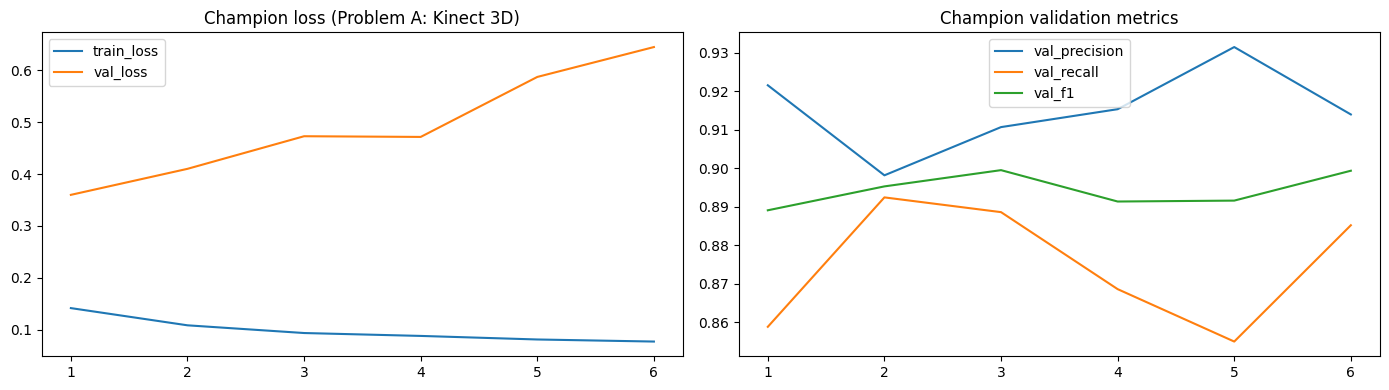

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(champion_history_df["epoch"], champion_history_df["train_loss"], label="train_loss")
axes[0].plot(champion_history_df["epoch"], champion_history_df["val_loss"],   label="val_loss")
axes[0].set_title("Champion loss (Problem A: Kinect 3D)")
axes[0].legend()

axes[1].plot(champion_history_df["epoch"], champion_history_df["val_precision"], label="val_precision")
axes[1].plot(champion_history_df["epoch"], champion_history_df["val_recall"],    label="val_recall")
axes[1].plot(champion_history_df["epoch"], champion_history_df["val_f1"],        label="val_f1")
axes[1].set_title("Champion validation metrics")
axes[1].legend()

plt.tight_layout()
plt.show()


### Predict on the independent test set

In [58]:
champion_model.eval()

with torch.no_grad():
    test_logits = champion_model(
        torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE))
    test_probs = torch.sigmoid(test_logits).cpu().numpy()
    test_preds = (test_probs >= CHAMPION_CONFIG["threshold"]).astype(int)

test_pred_df = meta_test.copy()
test_pred_df["prob"]  = test_probs
test_pred_df["pred"]  = test_preds
test_pred_df["label"] = y_test.astype(int)

display(test_pred_df.head())
print(test_pred_df.shape)


,sequence_id,frame_ref,label,start_frame,stop_frame,prob,pred
0,A113,2,0,78,152,0.001132,0
1,A113,3,0,78,152,0.001076,0
2,A113,4,0,78,152,0.000995,0
3,A113,5,0,78,152,0.001086,0
4,A113,6,0,78,152,0.001165,0


(3766, 7)


### Frame-level independent test metrics

In [59]:
test_precision  = precision_score(test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_recall     = recall_score(   test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_f1         = f1_score(       test_pred_df["label"], test_pred_df["pred"], zero_division=0)
test_f1_macro   = f1_score(       test_pred_df["label"], test_pred_df["pred"], average="macro",    zero_division=0)
test_f1_weighted= f1_score(       test_pred_df["label"], test_pred_df["pred"], average="weighted", zero_division=0)
test_cm         = confusion_matrix(test_pred_df["label"], test_pred_df["pred"])

print("Independent test metrics")
print("precision         :", test_precision)
print("recall            :", test_recall)
print("f1 (binary, 1)    :", test_f1)
print("f1_macro          :", test_f1_macro)
print("f1_weighted       :", test_f1_weighted)
print("\nConfusion matrix:")
print(test_cm)
print("\nClassification report:")
print(classification_report(test_pred_df["label"], test_pred_df["pred"], zero_division=0))


Independent test metrics
precision         : 0.9403361344537815
recall            : 0.9395465994962217
f1 (binary, 1)    : 0.9399412011759765
f1_macro          : 0.9183460518515261
f1_weighted       : 0.9240688237649093

Confusion matrix:
[[1242  142]
 [ 144 2238]]

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1384
           1       0.94      0.94      0.94      2382

    accuracy                           0.92      3766
   macro avg       0.92      0.92      0.92      3766
weighted avg       0.92      0.92      0.92      3766



### Per-sequence prediction summary

In [60]:
sequence_pred_summary = (
    test_pred_df.groupby("sequence_id")
    .agg(
        n_windows=("pred", "size"),
        n_true_positive_frames=("label", "sum"),
        n_pred_positive_frames=("pred",  "sum"),
        mean_prob=("prob", "mean"),
        max_prob=("prob",  "max"),
        start_frame=("start_frame", "first"),
        stop_frame=("stop_frame",   "first"),
    )
    .reset_index()
)

display(sequence_pred_summary.head(20))


,sequence_id,n_windows,n_true_positive_frames,n_pred_positive_frames,mean_prob,max_prob,start_frame,stop_frame
0,A113,188,75,111,0.585345,1.0,78,152
1,A114,219,61,80,0.379609,1.0,125,185
2,A117,231,214,231,0.858293,1.0,0,215
3,A121,237,217,213,0.816475,1.0,0,218
4,A138,346,218,199,0.558423,1.0,69,286
5,A140,162,106,72,0.477300,1.0,6,111
6,A159,135,76,77,0.588547,1.0,47,122
7,A16,194,121,107,0.579303,1.0,30,150
8,A17,191,122,127,0.657387,1.0,21,142
9,A25,173,100,88,0.529397,1.0,32,131


### Start/stop frame extraction helpers

In [61]:
def longest_positive_run(frame_df: pd.DataFrame, pred_col: str = "pred"):
    # Returns (start, end) of longest consecutive predicted-positive run, or (None, None)
    frame_df = frame_df.sort_values("frame_ref").reset_index(drop=True)

    best_start = best_end = None
    best_len = 0
    current_start = current_end = None

    for _, row in frame_df.iterrows():
        frame_no = int(row["frame_ref"])
        is_pos   = int(row[pred_col]) == 1

        if is_pos:
            if current_start is None:
                current_start = current_end = frame_no
            elif frame_no == current_end + 1:
                current_end = frame_no
            else:
                run_len = current_end - current_start + 1
                if run_len > best_len:
                    best_len, best_start, best_end = run_len, current_start, current_end
                current_start = current_end = frame_no
        else:
            if current_start is not None:
                run_len = current_end - current_start + 1
                if run_len > best_len:
                    best_len, best_start, best_end = run_len, current_start, current_end
                current_start = current_end = None

    if current_start is not None:
        run_len = current_end - current_start + 1
        if run_len > best_len:
            best_start, best_end = current_start, current_end

    return best_start, best_end


def threshold_run_from_prob(frame_df: pd.DataFrame, prob_col: str = "prob", threshold: float = 0.5):
    temp = frame_df.copy()
    temp["pred_tmp"] = (temp[prob_col] >= threshold).astype(int)
    return longest_positive_run(temp, pred_col="pred_tmp")


### Sequence-level application-context evaluation

In [62]:
sequence_rows = []

for sequence_id, seq_df in test_pred_df.groupby("sequence_id"):
    seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

    true_start = int(seq_df["start_frame"].iloc[0])
    true_stop  = int(seq_df["stop_frame"].iloc[0])

    pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

    if pred_start is None or pred_stop is None:
        start_error = stop_error = abs_start_error = abs_stop_error = np.nan
        detected = 0
    else:
        start_error     = pred_start - true_start
        stop_error      = pred_stop  - true_stop
        abs_start_error = abs(start_error)
        abs_stop_error  = abs(stop_error)
        detected = 1

    sequence_rows.append({
        "sequence_id":          sequence_id,
        "true_start":           true_start,
        "true_stop":            true_stop,
        "pred_start":           pred_start,
        "pred_stop":            pred_stop,
        "start_error_frames":   start_error,
        "stop_error_frames":    stop_error,
        "abs_start_error_frames": abs_start_error,
        "abs_stop_error_frames":  abs_stop_error,
        "detected_segment":     detected,
        "n_test_windows":       len(seq_df),
        "n_true_positive_windows": int(seq_df["label"].sum()),
        "n_pred_positive_windows": int(seq_df["pred"].sum()),
        "mean_prob": float(seq_df["prob"].mean()),
        "max_prob":  float(seq_df["prob"].max()),
    })

sequence_eval_df = pd.DataFrame(sequence_rows)
display(sequence_eval_df.head(20))


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,n_test_windows,n_true_positive_windows,n_pred_positive_windows,mean_prob,max_prob
0,A113,78,152,58,168,-20,16,20,16,1,188,75,111,0.585345,1.0
1,A114,125,185,122,200,-3,15,3,15,1,219,61,80,0.379609,1.0
2,A117,0,215,2,232,2,17,2,17,1,231,214,231,0.858293,1.0
3,A121,0,218,2,211,2,-7,2,7,1,237,217,213,0.816475,1.0
4,A138,69,286,88,286,19,0,19,0,1,346,218,199,0.558423,1.0
5,A140,6,111,32,103,26,-8,26,8,1,162,106,72,0.477300,1.0
6,A159,47,122,42,118,-5,-4,5,4,1,135,76,77,0.588547,1.0
7,A16,30,150,33,139,3,-11,3,11,1,194,121,107,0.579303,1.0
8,A17,21,142,24,150,3,8,3,8,1,191,122,127,0.657387,1.0
9,A25,32,131,35,122,3,-9,3,9,1,173,100,88,0.529397,1.0


### Summary of start/stop frame errors

In [63]:
sequence_eval_summary = pd.DataFrame({
    "metric": [
        "n_test_sequences",
        "n_detected_segments",
        "detection_rate",
        "mean_abs_start_error_frames",
        "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",
        "median_abs_stop_error_frames",
    ],
    "value": [
        len(sequence_eval_df),
        int(sequence_eval_df["detected_segment"].sum()),
        float(sequence_eval_df["detected_segment"].mean()),
        float(sequence_eval_df["abs_start_error_frames"].mean()),
        float(sequence_eval_df["abs_start_error_frames"].median()),
        float(sequence_eval_df["abs_stop_error_frames"].mean()),
        float(sequence_eval_df["abs_stop_error_frames"].median()),
    ],
})

display(sequence_eval_summary)


,metric,value
0,n_test_sequences,18.000000
1,n_detected_segments,18.000000
2,detection_rate,1.000000
3,mean_abs_start_error_frames,9.111111
4,median_abs_start_error_frames,4.000000
5,mean_abs_stop_error_frames,6.944444
6,median_abs_stop_error_frames,5.500000


### Inspect worst and best sequence boundary predictions

In [64]:
sequence_eval_ranked = sequence_eval_df.copy()
sequence_eval_ranked["total_abs_boundary_error"] = (
    sequence_eval_ranked["abs_start_error_frames"].fillna(9999) +
    sequence_eval_ranked["abs_stop_error_frames"].fillna(9999)
)

print("Best boundary predictions:")
display(sequence_eval_ranked.sort_values("total_abs_boundary_error", ascending=True).head(10))

print("Worst boundary predictions:")
display(sequence_eval_ranked.sort_values("total_abs_boundary_error", ascending=False).head(10))


Best boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,n_test_windows,n_true_positive_windows,n_pred_positive_windows,mean_prob,max_prob,total_abs_boundary_error
13,A59,2,214,2,213,0,-1,0,1,1,235,213,212,0.817112,1.0,1
17,B17,110,207,111,208,1,1,1,1,1,267,98,98,0.368164,1.0,2
12,A57,64,254,59,253,-5,-1,5,1,1,252,190,195,0.706889,1.0,6
3,A121,0,218,2,211,2,-7,2,7,1,237,217,213,0.816475,1.0,9
11,A30,41,130,48,128,7,-2,7,2,1,181,90,81,0.476063,1.0,9
6,A159,47,122,42,118,-5,-4,5,4,1,135,76,77,0.588547,1.0,9
8,A17,21,142,24,150,3,8,3,8,1,191,122,127,0.657387,1.0,11
9,A25,32,131,35,122,3,-9,3,9,1,173,100,88,0.529397,1.0,12
7,A16,30,150,33,139,3,-11,3,11,1,194,121,107,0.579303,1.0,14
15,A68,48,163,33,161,-15,-2,15,2,1,192,116,129,0.673027,1.0,17


Worst boundary predictions:


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,n_test_windows,n_true_positive_windows,n_pred_positive_windows,mean_prob,max_prob,total_abs_boundary_error
0,A113,78,152,58,168,-20,16,20,16,1,188,75,111,0.585345,1.0,36
16,A95,35,179,2,177,-33,-2,33,2,1,176,143,176,0.995400,1.0,35
5,A140,6,111,32,103,26,-8,26,8,1,162,106,72,0.477300,1.0,34
10,A27,38,116,39,97,1,-19,1,19,1,166,79,59,0.375227,1.0,20
2,A117,0,215,2,232,2,17,2,17,1,231,214,231,0.858293,1.0,19
4,A138,69,286,88,286,19,0,19,0,1,346,218,199,0.558423,1.0,19
14,A6,30,172,46,170,16,-2,16,2,1,221,143,125,0.588460,1.0,18
1,A114,125,185,122,200,-3,15,3,15,1,219,61,80,0.379609,1.0,18
15,A68,48,163,33,161,-15,-2,15,2,1,192,116,129,0.673027,1.0,17
7,A16,30,150,33,139,3,-11,3,11,1,194,121,107,0.579303,1.0,14


### Visualize one test sequence prediction

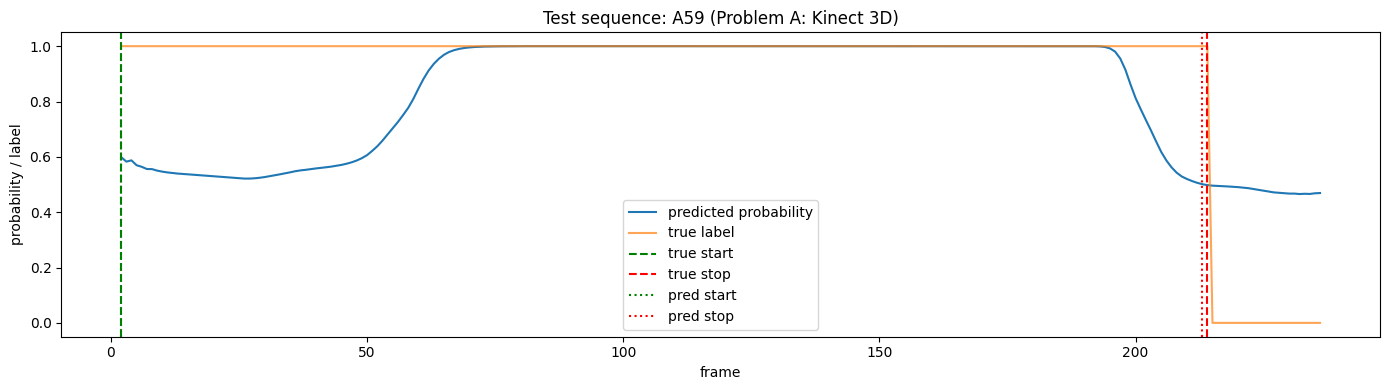

In [65]:
example_test_sequence_id = (
    sequence_eval_ranked.sort_values("total_abs_boundary_error").iloc[0]["sequence_id"]
)
plot_seq_df = test_pred_df[test_pred_df["sequence_id"] == example_test_sequence_id].copy()
plot_seq_df = plot_seq_df.sort_values("frame_ref")

true_start = int(plot_seq_df["start_frame"].iloc[0])
true_stop  = int(plot_seq_df["stop_frame"].iloc[0])
pred_start, pred_stop = longest_positive_run(plot_seq_df, pred_col="pred")

plt.figure(figsize=(14, 4))
plt.plot(plot_seq_df["frame_ref"], plot_seq_df["prob"],  label="predicted probability")
plt.plot(plot_seq_df["frame_ref"], plot_seq_df["label"], label="true label", alpha=0.7)
plt.axvline(true_start, linestyle="--", color="green", label="true start")
plt.axvline(true_stop,  linestyle="--", color="red",   label="true stop")
if pred_start is not None: plt.axvline(pred_start, linestyle=":", color="green", label="pred start")
if pred_stop  is not None: plt.axvline(pred_stop,  linestyle=":", color="red",   label="pred stop")
plt.title(f"Test sequence: {example_test_sequence_id} (Problem A: Kinect 3D)")
plt.xlabel("frame"); plt.ylabel("probability / label"); plt.legend()
plt.tight_layout(); plt.show()


### Save artifacts

In [66]:
test_pred_path              = output_dir / "a11_problem_a_test_predictions.csv"
sequence_eval_path          = output_dir / "a11_problem_a_sequence_eval.csv"
sequence_eval_summary_path  = output_dir / "a11_problem_a_sequence_eval_summary.csv"
history_path                = output_dir / "a11_problem_a_champion_history.csv"

test_pred_df.to_csv(test_pred_path,             index=False)
sequence_eval_df.to_csv(sequence_eval_path,     index=False)
sequence_eval_summary.to_csv(sequence_eval_summary_path, index=False)
champion_history_df.to_csv(history_path,        index=False)

print("Saved:")
for p in [test_pred_path, sequence_eval_path, sequence_eval_summary_path, history_path]:
    print(" ", p)


Saved:
  reporting\results\a11_problem_a_test_predictions.csv
  reporting\results\a11_problem_a_sequence_eval.csv
  reporting\results\a11_problem_a_sequence_eval_summary.csv
  reporting\results\a11_problem_a_champion_history.csv


### Log champion run to MLflow

In [67]:
with mlflow.start_run(run_name="problem_a_quick_champion_test_eval"):
    mlflow.log_param("problem",        "A")
    mlflow.log_param("task",           "inside_exercise_vs_outside_exercise")
    mlflow.log_param("feature_set",    CHAMPION_CONFIG["feature_set"])
    mlflow.log_param("seq_len",        CHAMPION_CONFIG["seq_len"])
    mlflow.log_param("hidden_dims",    str(CHAMPION_CONFIG["hidden_dims"]))
    mlflow.log_param("dropout",        CHAMPION_CONFIG["dropout"])
    mlflow.log_param("optimizer",      CHAMPION_CONFIG["optimizer"])
    mlflow.log_param("batch_size",     CHAMPION_CONFIG["batch_size"])
    mlflow.log_param("epochs",         CHAMPION_CONFIG["epochs"])
    mlflow.log_param("patience",       CHAMPION_CONFIG["patience"])
    mlflow.log_param("threshold",      CHAMPION_CONFIG["threshold"])
    mlflow.log_param("learning_rate",  LEARNING_RATE)
    mlflow.log_param("n_train_sequences", len(train_sequence_ids))
    mlflow.log_param("n_test_sequences",  len(test_sequence_ids))
    mlflow.log_param("n_train_windows",   int(len(y_train_all)))
    mlflow.log_param("n_test_windows",    int(len(y_test)))

    mlflow.log_metric("test_precision",                  float(test_precision))
    mlflow.log_metric("test_recall",                     float(test_recall))
    mlflow.log_metric("test_f1_binary",                  float(test_f1))
    mlflow.log_metric("test_f1_macro",                   float(test_f1_macro))
    mlflow.log_metric("test_f1_weighted",                float(test_f1_weighted))
    mlflow.log_metric("test_detection_rate",             float(sequence_eval_df["detected_segment"].mean()))
    mlflow.log_metric("test_mean_abs_start_error_frames",   float(sequence_eval_df["abs_start_error_frames"].mean()))
    mlflow.log_metric("test_mean_abs_stop_error_frames",    float(sequence_eval_df["abs_stop_error_frames"].mean()))
    mlflow.log_metric("test_median_abs_start_error_frames", float(sequence_eval_df["abs_start_error_frames"].median()))
    mlflow.log_metric("test_median_abs_stop_error_frames",  float(sequence_eval_df["abs_stop_error_frames"].median()))

    for p in [test_pred_path, sequence_eval_path, sequence_eval_summary_path, history_path]:
        mlflow.log_artifact(str(p))

    mlflow.pytorch.log_model(champion_model, artifact_path="model")

print("MLflow logging complete.")


2026/04/26 19:10:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/04/26 19:10:40 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is to set 'export_model' to True to save the pytorch model using the safe graph model format.
2026/04/26 19:10:40 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/04/26 19:10:46 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128).

🏃 View run problem_a_quick_champion_test_eval at: https://172.27.62.170:5001/#/experiments/30/runs/4f6715b2e6ee46b684365bb5674042a4
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/30
MLflow logging complete.


### Compact result summary for the report

In [68]:
report_summary = pd.DataFrame({
    "metric": [
        "test_precision", "test_recall",
        "test_f1_binary", "test_f1_macro", "test_f1_weighted",
        "test_detection_rate",
        "mean_abs_start_error_frames", "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",  "median_abs_stop_error_frames",
    ],
    "value": [
        test_precision, test_recall,
        test_f1, test_f1_macro, test_f1_weighted,
        float(sequence_eval_df["detected_segment"].mean()),
        float(sequence_eval_df["abs_start_error_frames"].mean()),
        float(sequence_eval_df["abs_start_error_frames"].median()),
        float(sequence_eval_df["abs_stop_error_frames"].mean()),
        float(sequence_eval_df["abs_stop_error_frames"].median()),
    ]
})

display(report_summary)


,metric,value
0,test_precision,0.940336
1,test_recall,0.939547
2,test_f1_binary,0.939941
3,test_f1_macro,0.918346
4,test_f1_weighted,0.924069
5,test_detection_rate,1.000000
6,mean_abs_start_error_frames,9.111111
7,median_abs_start_error_frames,4.000000
8,mean_abs_stop_error_frames,6.944444
9,median_abs_stop_error_frames,5.500000


### Define a focused longer training search around the winner

In [69]:
FINAL_FEATURE_SET_NAMES = ["coords_only"]
FINAL_SEQ_LENS          = [3, 5, 9]
FINAL_HIDDEN_CONFIGS    = [(128, 64), (256, 128)]
FINAL_DROPOUTS          = [0.1, 0.2, 0.3]
FINAL_OPTIMIZERS        = ["adam", "adamw"]

FINAL_BATCH_SIZE  = 32
FINAL_EPOCHS      = 50
FINAL_PATIENCE    = 8
FINAL_THRESHOLD   = 0.5
FINAL_STRIDE      = 1


### Focused CV search function

In [70]:
def run_final_cv_search():
    results = []

    for feature_set_name in FINAL_FEATURE_SET_NAMES:
        for seq_len in FINAL_SEQ_LENS:
            print(f"\n=== FINAL SEARCH | feature_set={feature_set_name} | seq_len={seq_len} ===")

            X_train_all, y_train_all, meta_train, X_test, y_test, meta_test = \
                prepare_train_test_arrays(feature_set_name, seq_len)

            X_train_all_flat = flatten_if_needed(X_train_all)
            groups = meta_train["sequence_id"].values
            n_splits_here = min(N_SPLITS, len(np.unique(groups)))

            if n_splits_here < 2:
                print("Skipping: not enough train sequences.")
                continue

            gkf = GroupKFold(n_splits=n_splits_here)

            for hidden_dims in FINAL_HIDDEN_CONFIGS:
                for dropout in FINAL_DROPOUTS:
                    for optimizer_name in FINAL_OPTIMIZERS:
                        fold_rows = []

                        for fold, (tr_idx, val_idx) in enumerate(
                            gkf.split(X_train_all_flat, y_train_all, groups=groups), start=1
                        ):
                            res = run_one_fold(
                                X_train_all_flat, y_train_all, meta_train,
                                tr_idx, val_idx, hidden_dims, dropout, optimizer_name,
                                FINAL_BATCH_SIZE, FINAL_EPOCHS, FINAL_PATIENCE, FINAL_THRESHOLD,
                            )
                            row = {
                                "feature_set": feature_set_name, "seq_len": seq_len,
                                "hidden_dims": str(hidden_dims), "dropout": dropout,
                                "optimizer": optimizer_name, "fold": fold,
                                "val_precision": res["precision"], "val_recall": res["recall"],
                                "val_f1": res["f1"], "val_loss": res["loss"],
                            }
                            fold_rows.append(row); results.append(row)

                        fd = pd.DataFrame(fold_rows)
                        print(
                            f"hidden={hidden_dims}, dropout={dropout}, opt={optimizer_name} | "
                            f"mean_f1={fd['val_f1'].mean():.4f}, "
                            f"mean_precision={fd['val_precision'].mean():.4f}, "
                            f"mean_recall={fd['val_recall'].mean():.4f}"
                        )

    return pd.DataFrame(results)


### Run the focused final search

In [71]:
final_results_df = run_final_cv_search()
print("Finished final search. Rows:", len(final_results_df))
display(final_results_df.head())



=== FINAL SEARCH | feature_set=coords_only | seq_len=3 ===
Epoch 001 | train_loss=0.1477 | val_loss=0.2299 | precision=0.9447 | recall=0.8233 | f1=0.8798
Early stopping at epoch 9
Epoch 001 | train_loss=0.1553 | val_loss=0.1565 | precision=0.9343 | recall=0.9438 | f1=0.9390
Early stopping at epoch 9
Epoch 001 | train_loss=0.1518 | val_loss=0.2096 | precision=0.9042 | recall=0.9149 | f1=0.9095
Early stopping at epoch 9
Epoch 001 | train_loss=0.1521 | val_loss=0.1869 | precision=0.9150 | recall=0.9284 | f1=0.9217
Epoch 010 | train_loss=0.0753 | val_loss=0.2193 | precision=0.9359 | recall=0.8967 | f1=0.9159
Early stopping at epoch 14
Epoch 001 | train_loss=0.1540 | val_loss=0.1698 | precision=0.9691 | recall=0.8232 | f1=0.8902
Epoch 010 | train_loss=0.0726 | val_loss=0.2074 | precision=0.9621 | recall=0.8694 | f1=0.9134
Early stopping at epoch 11
Epoch 001 | train_loss=0.1536 | val_loss=0.1248 | precision=0.9482 | recall=0.9208 | f1=0.9343
Epoch 010 | train_loss=0.0731 | val_loss=0.1681 

,feature_set,seq_len,hidden_dims,dropout,optimizer,fold,val_precision,val_recall,val_f1,val_loss
0,coords_only,3,"(128, 64)",0.1,adam,1,0.944738,0.823258,0.879825,0.229884
1,coords_only,3,"(128, 64)",0.1,adam,2,0.934268,0.943780,0.939000,0.156475
2,coords_only,3,"(128, 64)",0.1,adam,3,0.904184,0.914884,0.909502,0.209612
3,coords_only,3,"(128, 64)",0.1,adam,4,0.943954,0.886020,0.914070,0.155077
4,coords_only,3,"(128, 64)",0.1,adam,5,0.968703,0.852510,0.906900,0.158146


### Summarize the focused final search

In [72]:
final_summary_df = (
    final_results_df
    .groupby(["feature_set", "seq_len", "hidden_dims", "dropout", "optimizer"], as_index=False)
    .agg(
        mean_val_precision=("val_precision", "mean"),
        std_val_precision=("val_precision",  "std"),
        mean_val_recall=("val_recall",       "mean"),
        std_val_recall=("val_recall",        "std"),
        mean_val_f1=("val_f1",               "mean"),
        std_val_f1=("val_f1",                "std"),
        mean_val_loss=("val_loss",           "mean"),
    )
    .sort_values(["mean_val_f1", "mean_val_precision", "mean_val_recall"],
                 ascending=[False, False, False])
    .reset_index(drop=True)
)

display(final_summary_df)


,feature_set,seq_len,hidden_dims,dropout,optimizer,mean_val_precision,std_val_precision,mean_val_recall,std_val_recall,mean_val_f1,std_val_f1,mean_val_loss
0,coords_only,9,"(128, 64)",0.1,adamw,0.940492,0.026003,0.908924,0.036207,0.923854,0.020722,0.198432
1,coords_only,9,"(256, 128)",0.2,adam,0.929151,0.025850,0.917415,0.035225,0.922748,0.021321,0.211867
2,coords_only,9,"(256, 128)",0.3,adamw,0.932331,0.032184,0.913696,0.030519,0.922063,0.010619,0.200417
3,coords_only,9,"(128, 64)",0.2,adam,0.931485,0.038204,0.912549,0.030909,0.921292,0.024634,0.198948
4,coords_only,3,"(256, 128)",0.2,adamw,0.926729,0.032929,0.916474,0.030574,0.921003,0.021385,0.204267
5,coords_only,5,"(128, 64)",0.1,adamw,0.934790,0.030814,0.908663,0.047073,0.920526,0.024929,0.199291
6,coords_only,5,"(256, 128)",0.3,adamw,0.934984,0.025752,0.905182,0.041966,0.919065,0.021412,0.198451
7,coords_only,9,"(256, 128)",0.1,adam,0.934306,0.027961,0.905352,0.042073,0.918768,0.022064,0.209860
8,coords_only,5,"(128, 64)",0.2,adam,0.927729,0.024307,0.911035,0.039680,0.918747,0.023464,0.195168
9,coords_only,9,"(128, 64)",0.2,adamw,0.940931,0.034677,0.898117,0.036827,0.918364,0.024994,0.203279


### Save the focused final search

In [73]:
final_results_path = output_dir / "a11_problem_a_final_cv_results.csv"
final_summary_path = output_dir / "a11_problem_a_final_cv_summary.csv"

final_results_df.to_csv(final_results_path, index=False)
final_summary_df.to_csv(final_summary_path, index=False)

print("Saved:")
print(final_results_path)
print(final_summary_path)


Saved:
reporting\results\a11_problem_a_final_cv_results.csv
reporting\results\a11_problem_a_final_cv_summary.csv


### Pick the final champion from the focused search

In [74]:
best_row = final_summary_df.iloc[0].to_dict()
best_row


{'feature_set': 'coords_only',
 'seq_len': 9,
 'hidden_dims': '(128, 64)',
 'dropout': 0.1,
 'optimizer': 'adamw',
 'mean_val_precision': 0.9404917733612216,
 'std_val_precision': 0.026003365460258773,
 'mean_val_recall': 0.9089240598151666,
 'std_val_recall': 0.03620696588318629,
 'mean_val_f1': 0.9238539446139672,
 'std_val_f1': 0.020721551080740575,
 'mean_val_loss': 0.19843172312989976}

### Build final champion config from best row

In [75]:
FINAL_CHAMPION_CONFIG = {
    "feature_set": best_row["feature_set"],
    "seq_len":     int(best_row["seq_len"]),
    "hidden_dims": tuple(
        int(x.strip())
        for x in best_row["hidden_dims"].strip("()").split(",")
        if x.strip()
    ),
    "dropout":     float(best_row["dropout"]),
    "optimizer":   best_row["optimizer"],
    "batch_size":  32,
    "epochs":      80,
    "patience":    12,
    "threshold":   0.5,
}

FINAL_CHAMPION_CONFIG


{'feature_set': 'coords_only',
 'seq_len': 9,
 'hidden_dims': (128, 64),
 'dropout': 0.1,
 'optimizer': 'adamw',
 'batch_size': 32,
 'epochs': 80,
 'patience': 12,
 'threshold': 0.5}

### Prepare arrays for the final champion

In [76]:
X_train_all, y_train_all, meta_train, X_test, y_test, meta_test = prepare_train_test_arrays(
    feature_set_name=FINAL_CHAMPION_CONFIG["feature_set"],
    seq_len=FINAL_CHAMPION_CONFIG["seq_len"],
)

X_train_all_flat = flatten_if_needed(X_train_all)
X_test_flat      = flatten_if_needed(X_test)

final_scaler           = StandardScaler()
X_train_all_scaled     = final_scaler.fit_transform(X_train_all_flat)
X_test_scaled          = final_scaler.transform(X_test_flat)

n_pos_train            = int(y_train_all.sum())
n_neg_train            = int(len(y_train_all) - n_pos_train)
final_pos_weight_value = n_neg_train / max(n_pos_train, 1)
final_pos_weight_tensor = torch.tensor(
    [final_pos_weight_value], dtype=torch.float32, device=DEVICE)

print("Train windows:", X_train_all_scaled.shape, y_train_all.shape)
print("Test windows:", X_test_scaled.shape, y_test.shape)
print("Final pos_weight:", final_pos_weight_value)


Train windows: (32656, 351) (32656,)
Test windows: (3694, 351) (3694,)
Final pos_weight: 0.5265519820493643


### Validation split for early stopping

In [77]:
train_seq_ids_sorted = sorted(meta_train["sequence_id"].unique())

seq_train_ids_sub, seq_val_ids_sub = train_test_split(
    train_seq_ids_sorted, test_size=VALIDATION_SPLIT, random_state=RANDOM_SEED)

seq_train_ids_sub = set(seq_train_ids_sub)
seq_val_ids_sub   = set(seq_val_ids_sub)

train_mask_sub = meta_train["sequence_id"].isin(seq_train_ids_sub).values
val_mask_sub   = meta_train["sequence_id"].isin(seq_val_ids_sub).values

X_train_sub = X_train_all_scaled[train_mask_sub]
y_train_sub = y_train_all[train_mask_sub]
X_val_sub   = X_train_all_scaled[val_mask_sub]
y_val_sub   = y_train_all[val_mask_sub]

print("Final sub-train:", X_train_sub.shape, y_train_sub.shape)
print("Final sub-val  :", X_val_sub.shape, y_val_sub.shape)


Final sub-train: (29144, 351) (29144,)
Final sub-val  : (3512, 351) (3512,)


### Train the final champion

In [78]:
train_dataset_sub = FrameWindowDataset(X_train_sub, y_train_sub)
val_dataset_sub   = FrameWindowDataset(X_val_sub,   y_val_sub)

train_loader_sub = DataLoader(train_dataset_sub, batch_size=FINAL_CHAMPION_CONFIG["batch_size"],
                              shuffle=True,  num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader_sub   = DataLoader(val_dataset_sub,   batch_size=FINAL_CHAMPION_CONFIG["batch_size"],
                              shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

final_champion_model = DenseBinaryClassifier(
    input_dim=X_train_all_scaled.shape[1],
    hidden_dims=FINAL_CHAMPION_CONFIG["hidden_dims"],
    dropout=FINAL_CHAMPION_CONFIG["dropout"],
).to(DEVICE)

final_champion_model, final_history_df = train_binary_classifier(
    final_champion_model, train_loader_sub, val_loader_sub,
    optimizer_name=FINAL_CHAMPION_CONFIG["optimizer"], learning_rate=LEARNING_RATE,
    epochs=FINAL_CHAMPION_CONFIG["epochs"], patience=FINAL_CHAMPION_CONFIG["patience"],
    pos_weight=final_pos_weight_tensor, threshold=FINAL_CHAMPION_CONFIG["threshold"],
)

display(final_history_df.tail())


Epoch 001 | train_loss=0.1344 | val_loss=0.3645 | precision=0.9260 | recall=0.8328 | f1=0.8769
Epoch 010 | train_loss=0.0598 | val_loss=0.5687 | precision=0.9256 | recall=0.8754 | f1=0.8998
Early stopping at epoch 13


,epoch,train_loss,val_loss,val_precision,val_recall,val_f1
8,9,0.062813,0.561787,0.922449,0.867747,0.894262
9,10,0.059758,0.568710,0.925575,0.875427,0.899803
10,11,0.060052,0.819964,0.913466,0.882679,0.897809
11,12,0.055400,0.669565,0.922352,0.876706,0.898950
12,13,0.055172,0.648492,0.935909,0.878413,0.906250


### Evaluate the final champion on independent test data

In [79]:
final_champion_model.eval()

with torch.no_grad():
    final_test_logits = final_champion_model(
        torch.tensor(X_test_scaled, dtype=torch.float32, device=DEVICE))
    final_test_probs = torch.sigmoid(final_test_logits).cpu().numpy()
    final_test_preds = (final_test_probs >= FINAL_CHAMPION_CONFIG["threshold"]).astype(int)

final_test_pred_df = meta_test.copy()
final_test_pred_df["prob"]  = final_test_probs
final_test_pred_df["pred"]  = final_test_preds
final_test_pred_df["label"] = y_test.astype(int)

final_test_precision   = precision_score(final_test_pred_df["label"], final_test_pred_df["pred"], zero_division=0)
final_test_recall      = recall_score(   final_test_pred_df["label"], final_test_pred_df["pred"], zero_division=0)
final_test_f1          = f1_score(       final_test_pred_df["label"], final_test_pred_df["pred"], zero_division=0)
final_test_f1_macro    = f1_score(       final_test_pred_df["label"], final_test_pred_df["pred"], average="macro",    zero_division=0)
final_test_f1_weighted = f1_score(       final_test_pred_df["label"], final_test_pred_df["pred"], average="weighted", zero_division=0)
final_test_cm          = confusion_matrix(final_test_pred_df["label"], final_test_pred_df["pred"])

print("Final independent test metrics")
print("precision         :", final_test_precision)
print("recall            :", final_test_recall)
print("f1 (binary, 1)    :", final_test_f1)
print("f1_macro          :", final_test_f1_macro)
print("f1_weighted       :", final_test_f1_weighted)
print("\nConfusion matrix:")
print(final_test_cm)
print("\nClassification report:")
print(classification_report(final_test_pred_df["label"], final_test_pred_df["pred"], zero_division=0))


Final independent test metrics
precision         : 0.9532502226179875
recall            : 0.9026138279932546
f1 (binary, 1)    : 0.9272412299696838
f1_macro          : 0.902970795490257
f1_weighted       : 0.9098695383715234

Confusion matrix:
[[1217  105]
 [ 231 2141]]

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.92      0.88      1322
           1       0.95      0.90      0.93      2372

    accuracy                           0.91      3694
   macro avg       0.90      0.91      0.90      3694
weighted avg       0.91      0.91      0.91      3694



### Final boundary evaluation

In [80]:
final_sequence_rows = []

for sequence_id, seq_df in final_test_pred_df.groupby("sequence_id"):
    seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

    true_start = int(seq_df["start_frame"].iloc[0])
    true_stop  = int(seq_df["stop_frame"].iloc[0])

    pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

    if pred_start is None or pred_stop is None:
        start_error = stop_error = abs_start_error = abs_stop_error = np.nan
        detected = 0
    else:
        start_error     = pred_start - true_start
        stop_error      = pred_stop  - true_stop
        abs_start_error = abs(start_error)
        abs_stop_error  = abs(stop_error)
        detected = 1

    final_sequence_rows.append({
        "sequence_id":              sequence_id,
        "true_start":               true_start,
        "true_stop":                true_stop,
        "pred_start":               pred_start,
        "pred_stop":                pred_stop,
        "start_error_frames":       start_error,
        "stop_error_frames":        stop_error,
        "abs_start_error_frames":   abs_start_error,
        "abs_stop_error_frames":    abs_stop_error,
        "detected_segment":         detected,
    })

final_sequence_eval_df = pd.DataFrame(final_sequence_rows)

final_sequence_eval_summary = pd.DataFrame({
    "metric": [
        "n_test_sequences", "n_detected_segments", "detection_rate",
        "mean_abs_start_error_frames", "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",  "median_abs_stop_error_frames",
    ],
    "value": [
        len(final_sequence_eval_df),
        int(final_sequence_eval_df["detected_segment"].sum()),
        float(final_sequence_eval_df["detected_segment"].mean()),
        float(final_sequence_eval_df["abs_start_error_frames"].mean()),
        float(final_sequence_eval_df["abs_start_error_frames"].median()),
        float(final_sequence_eval_df["abs_stop_error_frames"].mean()),
        float(final_sequence_eval_df["abs_stop_error_frames"].median()),
    ],
})

display(final_sequence_eval_summary)


,metric,value
0,n_test_sequences,18.000000
1,n_detected_segments,18.000000
2,detection_rate,1.000000
3,mean_abs_start_error_frames,13.777778
4,median_abs_start_error_frames,4.000000
5,mean_abs_stop_error_frames,8.277778
6,median_abs_stop_error_frames,7.500000


### Log the final champion to MLflow

In [81]:
final_test_pred_path              = output_dir / "a11_problem_a_final_test_predictions.csv"
final_sequence_eval_path          = output_dir / "a11_problem_a_final_sequence_eval.csv"
final_sequence_eval_summary_path  = output_dir / "a11_problem_a_final_sequence_eval_summary.csv"
final_history_path                = output_dir / "a11_problem_a_final_history.csv"

final_test_pred_df.to_csv(final_test_pred_path,                     index=False)
final_sequence_eval_df.to_csv(final_sequence_eval_path,             index=False)
final_sequence_eval_summary.to_csv(final_sequence_eval_summary_path, index=False)
final_history_df.to_csv(final_history_path,                         index=False)

with mlflow.start_run(run_name="problem_a_final_champion_test_eval"):
    for k, v in FINAL_CHAMPION_CONFIG.items():
        mlflow.log_param(k, str(v) if isinstance(v, tuple) else v)

    mlflow.log_param("problem",             "A")
    mlflow.log_param("task",                "inside_exercise_vs_outside_exercise")
    mlflow.log_param("learning_rate",       LEARNING_RATE)
    mlflow.log_param("n_train_sequences",   len(train_sequence_ids))
    mlflow.log_param("n_test_sequences",    len(test_sequence_ids))
    mlflow.log_param("n_train_windows",     int(len(y_train_all)))
    mlflow.log_param("n_test_windows",      int(len(y_test)))

    mlflow.log_metric("test_precision",                   float(final_test_precision))
    mlflow.log_metric("test_recall",                      float(final_test_recall))
    mlflow.log_metric("test_f1_binary",                   float(final_test_f1))
    mlflow.log_metric("test_f1_macro",                    float(final_test_f1_macro))
    mlflow.log_metric("test_f1_weighted",                 float(final_test_f1_weighted))
    mlflow.log_metric("test_detection_rate",              float(final_sequence_eval_df["detected_segment"].mean()))
    mlflow.log_metric("test_mean_abs_start_error_frames",    float(final_sequence_eval_df["abs_start_error_frames"].mean()))
    mlflow.log_metric("test_mean_abs_stop_error_frames",     float(final_sequence_eval_df["abs_stop_error_frames"].mean()))
    mlflow.log_metric("test_median_abs_start_error_frames",  float(final_sequence_eval_df["abs_start_error_frames"].median()))
    mlflow.log_metric("test_median_abs_stop_error_frames",   float(final_sequence_eval_df["abs_stop_error_frames"].median()))

    for p in [final_test_pred_path, final_sequence_eval_path,
              final_sequence_eval_summary_path, final_history_path]:
        mlflow.log_artifact(str(p))

    mlflow.pytorch.log_model(final_champion_model, artifact_path="model")

print("Final MLflow logging complete.")


2026/04/26 21:05:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/04/26 21:05:54 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is to set 'export_model' to True to save the pytorch model using the safe graph model format.
2026/04/26 21:05:54 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.11.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/04/26 21:06:00 WARNING mlflow.utils.requirements_utils: Found torch version (2.11.0+cu128) contains a local version label (+cu128).

🏃 View run problem_a_final_champion_test_eval at: https://172.27.62.170:5001/#/experiments/30/runs/4e7c0e853cf14b858a2c4b1bfcc45b4c
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/30
Final MLflow logging complete.


### Final compact summary table

In [82]:
final_report_summary = pd.DataFrame({
    "metric": [
        "test_precision", "test_recall",
        "test_f1_binary", "test_f1_macro", "test_f1_weighted",
        "test_detection_rate",
        "mean_abs_start_error_frames", "median_abs_start_error_frames",
        "mean_abs_stop_error_frames",  "median_abs_stop_error_frames",
    ],
    "value": [
        final_test_precision, final_test_recall,
        final_test_f1, final_test_f1_macro, final_test_f1_weighted,
        float(final_sequence_eval_df["detected_segment"].mean()),
        float(final_sequence_eval_df["abs_start_error_frames"].mean()),
        float(final_sequence_eval_df["abs_start_error_frames"].median()),
        float(final_sequence_eval_df["abs_stop_error_frames"].mean()),
        float(final_sequence_eval_df["abs_stop_error_frames"].median()),
    ]
})

display(final_report_summary)


,metric,value
0,test_precision,0.953250
1,test_recall,0.902614
2,test_f1_binary,0.927241
3,test_f1_macro,0.902971
4,test_f1_weighted,0.909870
5,test_detection_rate,1.000000
6,mean_abs_start_error_frames,13.777778
7,median_abs_start_error_frames,4.000000
8,mean_abs_stop_error_frames,8.277778
9,median_abs_stop_error_frames,7.500000


### Analytic cell
Confusion matrix plot, Boundary error distribution, Per-sequence start/stop boundary errors, Plot best, median, and worst test sequence predictions

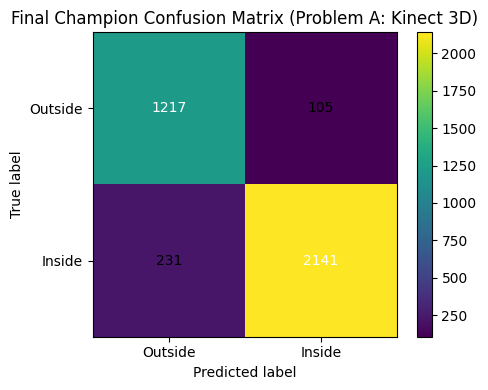

In [83]:
fig, ax = plt.subplots(figsize=(5, 4))

im = ax.imshow(final_test_cm)
ax.set_title("Final Champion Confusion Matrix (Problem A: Kinect 3D)")
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Outside", "Inside"]); ax.set_yticklabels(["Outside", "Inside"])

for i in range(final_test_cm.shape[0]):
    for j in range(final_test_cm.shape[1]):
        ax.text(j, i, final_test_cm[i, j], ha="center", va="center",
                color="white" if final_test_cm[i, j] > final_test_cm.max() / 2 else "black")

plt.colorbar(im)
plt.tight_layout(); plt.show()


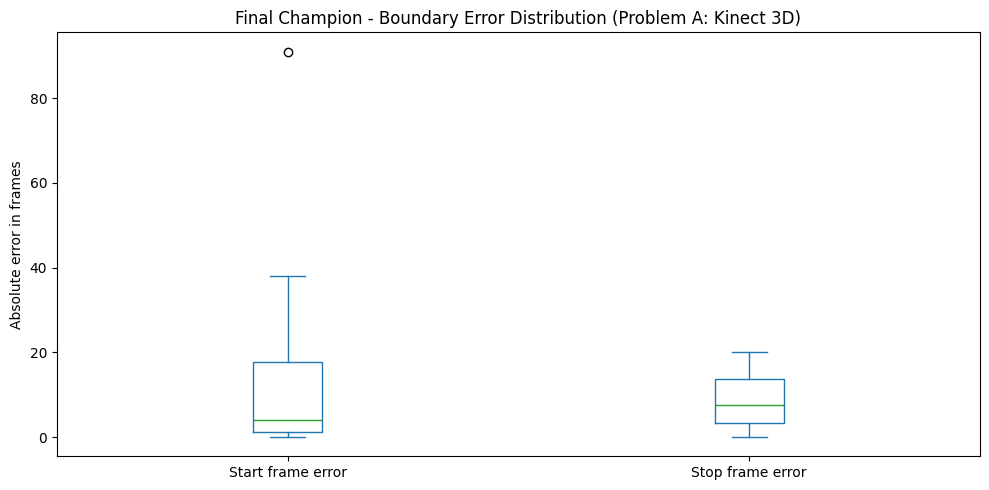

,start_error_abs,stop_error_abs
count,18.000000,18.000000
mean,13.777778,8.277778
std,22.451400,6.095375
min,0.000000,0.000000
25%,1.250000,3.250000
50%,4.000000,7.500000
75%,17.750000,13.750000
max,91.000000,20.000000


In [84]:
fig, ax = plt.subplots(figsize=(10, 5))

boundary_errors = pd.DataFrame({
    "start_error_abs": final_sequence_eval_df["abs_start_error_frames"],
    "stop_error_abs":  final_sequence_eval_df["abs_stop_error_frames"],
})

boundary_errors.plot(kind="box", ax=ax)
ax.set_title("Final Champion - Boundary Error Distribution (Problem A: Kinect 3D)")
ax.set_ylabel("Absolute error in frames")
ax.set_xticklabels(["Start frame error", "Stop frame error"])
plt.tight_layout(); plt.show()

display(boundary_errors.describe())


,sequence_id,true_start,true_stop,pred_start,pred_stop,start_error_frames,stop_error_frames,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
4,A138,69,286,160,280,91,-6,91,6,1,97
13,A59,2,214,40,204,38,-10,38,10,1,48
0,A113,78,152,58,168,-20,16,20,16,1,36
16,A95,35,179,4,175,-31,-4,31,4,1,35
5,A140,6,111,31,104,25,-7,25,7,1,32
12,A57,64,254,66,234,2,-20,2,20,1,22
7,A16,30,150,34,134,4,-16,4,16,1,20
2,A117,0,215,4,230,4,15,4,15,1,19
10,A27,38,116,38,100,0,-16,0,16,1,16
15,A68,48,163,37,160,-11,-3,11,3,1,14


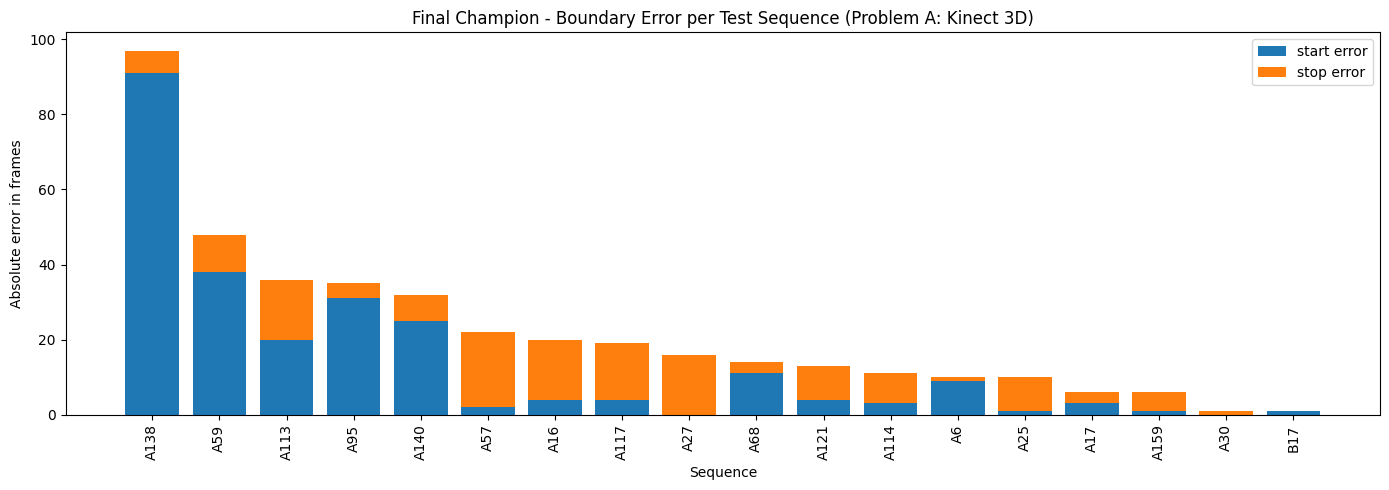

In [85]:
plot_boundary_df = final_sequence_eval_df.copy()
plot_boundary_df["total_abs_error"] = (
    plot_boundary_df["abs_start_error_frames"] +
    plot_boundary_df["abs_stop_error_frames"]
)
plot_boundary_df = plot_boundary_df.sort_values("total_abs_error", ascending=False)

display(plot_boundary_df)

plt.figure(figsize=(14, 5))
plt.bar(plot_boundary_df["sequence_id"],
        plot_boundary_df["abs_start_error_frames"], label="start error")
plt.bar(plot_boundary_df["sequence_id"],
        plot_boundary_df["abs_stop_error_frames"],
        bottom=plot_boundary_df["abs_start_error_frames"], label="stop error")
plt.title("Final Champion - Boundary Error per Test Sequence (Problem A: Kinect 3D)")
plt.xlabel("Sequence"); plt.ylabel("Absolute error in frames")
plt.xticks(rotation=90); plt.legend()
plt.tight_layout(); plt.show()


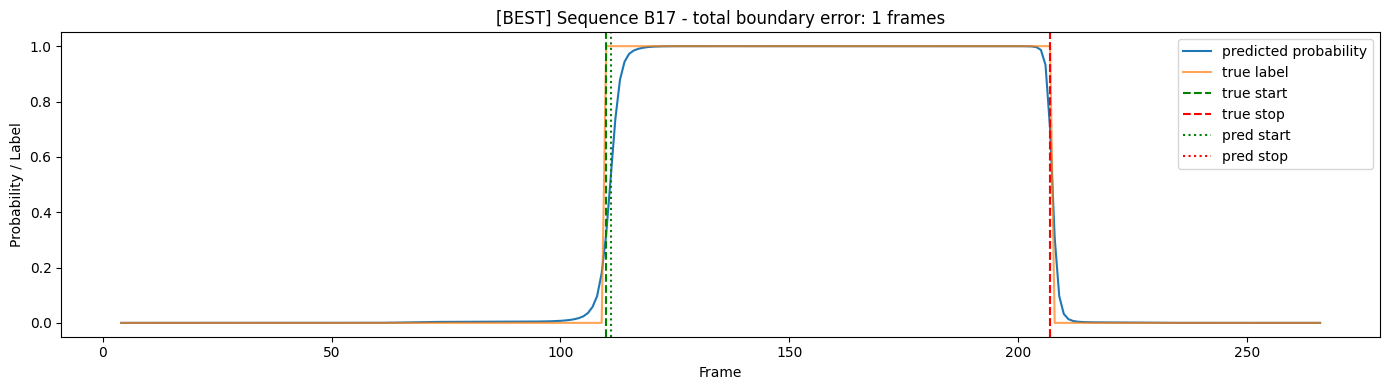

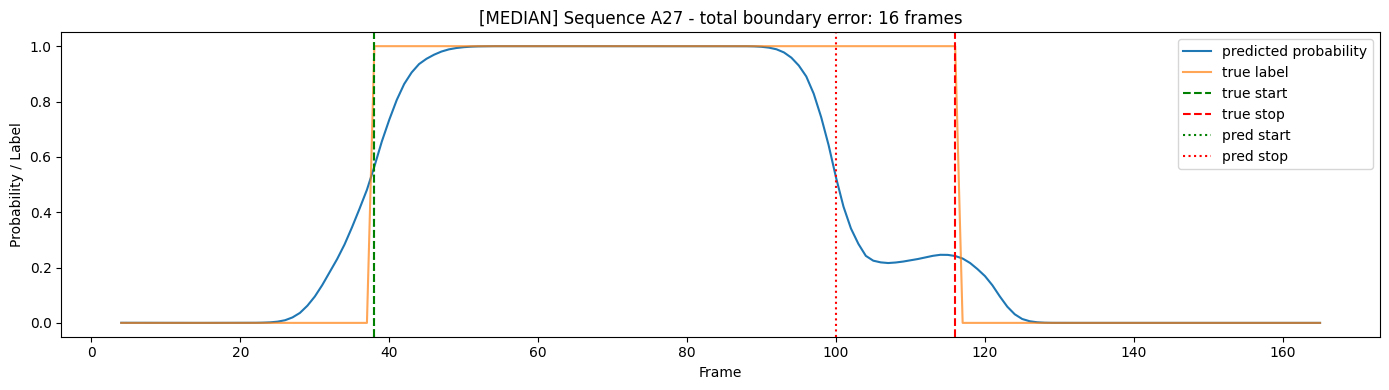

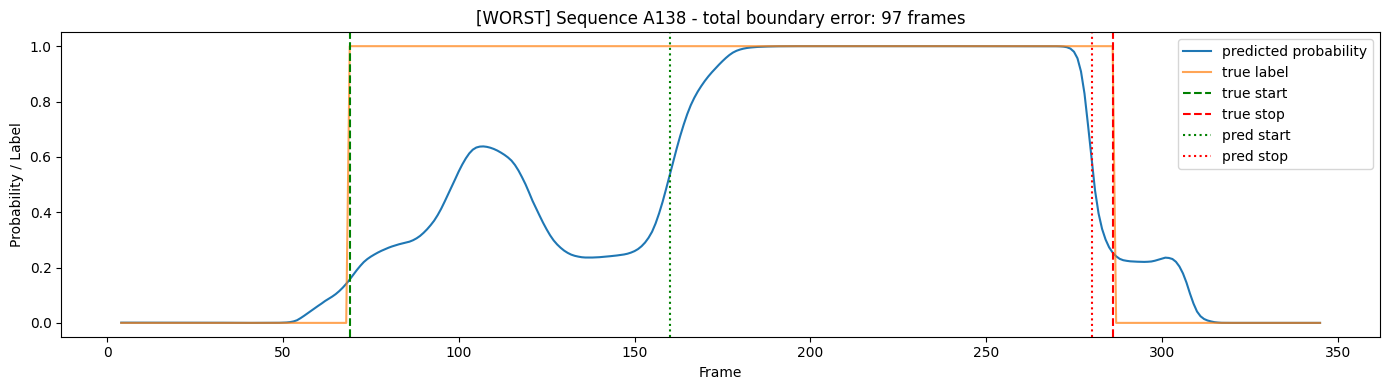

In [86]:
ranked_sequences = final_sequence_eval_df.copy()
ranked_sequences["total_abs_error"] = (
    ranked_sequences["abs_start_error_frames"] +
    ranked_sequences["abs_stop_error_frames"]
)

best_seq   = ranked_sequences.sort_values("total_abs_error").iloc[0]["sequence_id"]
median_seq = ranked_sequences.sort_values("total_abs_error").iloc[len(ranked_sequences) // 2]["sequence_id"]
worst_seq  = ranked_sequences.sort_values("total_abs_error", ascending=False).iloc[0]["sequence_id"]

for seq_label, sequence_id in [("best", best_seq), ("median", median_seq), ("worst", worst_seq)]:
    plot_seq_df = final_test_pred_df[final_test_pred_df["sequence_id"] == sequence_id].copy()
    plot_seq_df = plot_seq_df.sort_values("frame_ref")

    true_start = int(plot_seq_df["start_frame"].iloc[0])
    true_stop  = int(plot_seq_df["stop_frame"].iloc[0])
    pred_start, pred_stop = longest_positive_run(plot_seq_df, pred_col="pred")

    total_error = ranked_sequences.loc[
        ranked_sequences["sequence_id"] == sequence_id, "total_abs_error"].iloc[0]

    plt.figure(figsize=(14, 4))
    plt.plot(plot_seq_df["frame_ref"], plot_seq_df["prob"],  label="predicted probability")
    plt.plot(plot_seq_df["frame_ref"], plot_seq_df["label"], label="true label", alpha=0.7)
    plt.axvline(true_start, linestyle="--", color="green", label="true start")
    plt.axvline(true_stop,  linestyle="--", color="red",   label="true stop")
    if pred_start is not None: plt.axvline(pred_start, linestyle=":", color="green", label="pred start")
    if pred_stop  is not None: plt.axvline(pred_stop,  linestyle=":", color="red",   label="pred stop")
    plt.title(f"[{seq_label.upper()}] Sequence {sequence_id} - total boundary error: {total_error:.0f} frames")
    plt.xlabel("Frame"); plt.ylabel("Probability / Label"); plt.legend()
    plt.tight_layout(); plt.show()


In [87]:
# Final table: boundary predictions for ALL sequences
ALL_FEATURE_COLS = FEATURE_SETS[FINAL_CHAMPION_CONFIG["feature_set"]]

X_all, y_all, meta_all = make_windows_for_all_sequences(
    all_feat_df, feature_cols=ALL_FEATURE_COLS,
    seq_len=FINAL_CHAMPION_CONFIG["seq_len"], stride=FINAL_STRIDE,
)

X_all_flat  = flatten_if_needed(X_all)
X_all_scaled = final_scaler.transform(X_all_flat)

final_champion_model.eval()

with torch.no_grad():
    all_logits = final_champion_model(
        torch.tensor(X_all_scaled, dtype=torch.float32, device=DEVICE))
    all_probs = torch.sigmoid(all_logits).cpu().numpy()
    all_preds = (all_probs >= FINAL_CHAMPION_CONFIG["threshold"]).astype(int)

all_pred_df = meta_all.copy()
all_pred_df["prob"]  = all_probs
all_pred_df["pred"]  = all_preds
all_pred_df["label"] = y_all.astype(int)

all_sequence_rows = []

for sequence_id, seq_df in all_pred_df.groupby("sequence_id"):
    seq_df = seq_df.sort_values("frame_ref").reset_index(drop=True)

    true_start = int(seq_df["start_frame"].iloc[0])
    true_stop  = int(seq_df["stop_frame"].iloc[0])
    pred_start, pred_stop = longest_positive_run(seq_df, pred_col="pred")

    if pred_start is None or pred_stop is None:
        abs_start_error = abs_stop_error = np.nan; detected = 0
    else:
        abs_start_error = abs(pred_start - true_start)
        abs_stop_error  = abs(pred_stop  - true_stop)
        detected = 1

    all_sequence_rows.append({
        "sequence_id": sequence_id,
        "true_start": true_start, "true_stop": true_stop,
        "pred_start": pred_start, "pred_stop": pred_stop,
        "abs_start_error_frames": abs_start_error,
        "abs_stop_error_frames":  abs_stop_error,
        "detected_segment":       detected,
    })

all_sequence_eval_df = pd.DataFrame(all_sequence_rows)

print(f"All sequences: {len(all_sequence_eval_df)}")
print(f"Detection rate: {all_sequence_eval_df['detected_segment'].mean():.3f}")
print(f"Mean start error: {all_sequence_eval_df['abs_start_error_frames'].mean():.1f} frames")
print(f"Mean stop  error: {all_sequence_eval_df['abs_stop_error_frames'].mean():.1f} frames")

display(all_sequence_eval_df.head(20))


All sequences: 179
Detection rate: 1.000
Mean start error: 8.4 frames
Mean stop  error: 7.4 frames


,sequence_id,true_start,true_stop,pred_start,pred_stop,abs_start_error_frames,abs_stop_error_frames,detected_segment
0,A1,68,179,71,181,3,2,1
1,A10,42,202,67,198,25,4,1
2,A100,3,165,7,161,4,4,1
3,A101,2,230,6,226,4,4,1
4,A102,5,210,9,201,4,9,1
5,A103,54,221,58,217,4,4,1
6,A104,2,154,4,158,2,4,1
7,A105,1,146,4,148,3,2,1
8,A106,6,164,4,169,2,5,1
9,A108,131,284,120,283,11,1,1


In [88]:
# Top 20 worst and best boundary predictions across ALL sequences
all_sequence_eval_df["total_abs_error"] = (
    all_sequence_eval_df["abs_start_error_frames"] +
    all_sequence_eval_df["abs_stop_error_frames"]
)

print("Top 20 best:")
display(all_sequence_eval_df.sort_values("total_abs_error").head(20))

print("Top 20 worst:")
display(all_sequence_eval_df.sort_values("total_abs_error", ascending=False).head(20))


Top 20 best:


,sequence_id,true_start,true_stop,pred_start,pred_stop,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
175,B6,157,262,157,262,0,0,1,0
166,B18,108,196,108,196,0,0,1,0
177,B8,108,195,108,195,0,0,1,0
178,B9,96,183,97,183,1,0,1,1
176,B7,123,218,123,219,0,1,1,1
165,B17,110,207,111,207,1,0,1,1
86,A34,40,133,40,132,0,1,1,1
158,B10,108,193,109,193,1,0,1,1
82,A30,41,130,41,129,0,1,1,1
171,B22,90,173,90,171,0,2,1,2


Top 20 worst:


,sequence_id,true_start,true_stop,pred_start,pred_stop,abs_start_error_frames,abs_stop_error_frames,detected_segment,total_abs_error
144,A88,1,258,89,207,88,51,1,139
34,A130,1,236,107,259,106,23,1,129
42,A138,69,286,160,280,91,6,1,97
106,A52,21,173,43,130,22,43,1,65
141,A85,35,232,4,265,31,33,1,64
39,A135,13,125,30,92,17,33,1,50
113,A59,2,214,40,204,38,10,1,48
29,A126,144,260,116,243,28,17,1,45
159,B11,70,190,114,190,44,0,1,44
112,A58,1,227,4,265,3,38,1,41


### Example usage: make predictions with the champion model

In [89]:
# Example usage: make predictions with the champion model on any Kinect uncut sequence
def predict_kinect_sequence(kinect_uncut_path: str, kinect_cut_path: str) -> pd.DataFrame:
    # Given uncut+cut Kinect CSVs, return frame-level prob/pred for inside-exercise
    seq_df = load_kinect_uncut_df(kinect_uncut_path)
    start_frame, stop_frame = load_kinect_cut_bounds(kinect_cut_path, kinect_uncut_path)
    seq_df = add_inside_exercise_label(seq_df, start_frame, stop_frame)
    seq_df["sequence_id"] = "inference"
    seq_df["start_frame"] = start_frame
    seq_df["stop_frame"]  = stop_frame

    seq_df = add_normalized_coordinates(seq_df)
    seq_df = add_selected_distances(seq_df)
    seq_df = add_selected_angles(seq_df)
    seq_df = add_simple_velocity_features(seq_df)

    feature_cols = FEATURE_SETS[FINAL_CHAMPION_CONFIG["feature_set"]]
    X_seq, y_seq, frame_refs = make_sequence_windows(
        seq_df, feature_cols=feature_cols,
        seq_len=FINAL_CHAMPION_CONFIG["seq_len"], stride=1,
    )

    X_flat   = flatten_if_needed(X_seq)
    X_scaled = final_scaler.transform(X_flat)

    final_champion_model.eval()
    with torch.no_grad():
        logits = final_champion_model(
            torch.tensor(X_scaled, dtype=torch.float32, device=DEVICE))
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs >= FINAL_CHAMPION_CONFIG["threshold"]).astype(int)

    result = pd.DataFrame({
        "frame_index": frame_refs,
        "true_label":  y_seq.astype(int),
        "prob":        probs,
        "pred":        preds,
    })

    pred_start, pred_stop = longest_positive_run(
        result.rename(columns={"frame_index": "frame_ref"}), pred_col="pred")
    print(f"Ground truth: start={start_frame}, stop={stop_frame}")
    print(f"Predicted  : start={pred_start}, stop={pred_stop}")
    return result


# Demo with the example file
demo_result = predict_kinect_sequence(
    EXAMPLE_KINECT_UNCUT_PATH,
    EXAMPLE_KINECT_CUT_PATH,
)
display(demo_result.head(10))


Ground truth: start=68, stop=179
Predicted  : start=71, stop=181


,frame_index,true_label,prob,pred
0,4,0,0.000315,0
1,5,0,0.000295,0
2,6,0,0.000265,0
3,7,0,0.000215,0
4,8,0,0.000176,0
5,9,0,0.000133,0
6,10,0,0.000089,0
7,11,0,0.000058,0
8,12,0,0.000037,0
9,13,0,0.000023,0
